# 🦠 COVID-19 in India — An End-to-End Exploratory Data Analysis

**Author:** Data Science Portfolio Project
**Date range covered:** 30-Jan-2020 &rarr; 16-May-2021 (second wave peak period)
**Datasets:** State-wise confirmed cases, state-wise testing, and state-wise vaccination (India)

---

### 1. Introduction

This notebook presents a complete, reproducible exploratory data analysis (EDA) of three
complementary COVID-19 tables for **India**. The three files live side-by-side and describe the
same pandemic from three different operational angles: **infection**, **testing**, and
**vaccination**. Together they allow us to move from pure description ("what happened?") towards
explanation ("why / when did it happen, and what is associated with what?").

The design of this notebook follows the structure of a professional data-science deliverable:

| Section | What it contains |
|---|---|
| 1. Introduction | Context, provenance, variable dictionary |
| 2. Initial Questions | The questions driving the analysis |
| 3. Initial Exploration | Shape, structure, dtypes, quality issues, emerging patterns |
| 4. Data Preparation | Cleaning, standardisation, feature engineering |
| 5. Descriptive Statistics | Central tendency, dispersion, shape of distributions |
| 6. Visual Analysis (Univariate & Multivariate) | Distributions, box plots, scatter, correlation |
| 7. Time-Series & Comparative Analysis | National & state trends, waves, vaccination ramp-up |
| 8. Statistical Testing | Correlation, lag analysis, hypothesis tests |
| 9. Insights & Conclusion | Answers to the questions, surprises, next steps |

Every code block is followed by a **📝 Observation(s)** note in plain language, so the notebook can
be read as a report without executing the code.

### Dataset provenance & variable dictionary

All three files are **cumulative, state-wise, daily time series** for India.

#### A. `covid_19_india.csv` — Confirmed / Recovered / Deaths (14,978 rows × 9 cols)

| Column | Type (raw) | Meaning |
|---|---|---|
| `Sno` | int | Serial number (not needed for analysis) |
| `Date` | string | Observation date (YYYY-MM-DD) |
| `Time` | string | Reporting timestamp (inconsistent — several different times) |
| `State/UnionTerritory` | string | State / UT name |
| `ConfirmedIndianNational` | object | Confirmed cases among Indian nationals (with `-` placeholders) |
| `ConfirmedForeignNational` | object | Confirmed cases among foreign nationals (with `-` placeholders) |
| `Cured` | int | **Cumulative** recovered |
| `Deaths` | int | **Cumulative** deaths |
| `Confirmed` | int | **Cumulative** confirmed cases |

#### B. `StatewiseTestingDetails.csv` — Testing (13,300 rows × 5 cols)

| Column | Type (raw) | Meaning |
|---|---|---|
| `Date` | string | Observation date |
| `State` | string | State / UT name |
| `TotalSamples` | float | **Cumulative** samples tested |
| `Negative` | object | Cumulative negative samples (has blanks/`' '`) |
| `Positive` | float | Cumulative positive samples (heavily missing) |

#### C. `covid_vaccine_statewise.csv` — Vaccination (4,440 rows × 18 cols)

| Column | Meaning |
|---|---|
| `Updated On`, `State` | Date and State (includes an aggregate `India` row) |
| `Total Individuals Vaccinated`, `First/Second Dose Administered` | Cumulative dose counts |
| `Total Sessions Conducted`, `Total Sites` | Vaccination logistics |
| `Male/Female/Transgender (Individuals Vaccinated)` | Gender split |
| `Total Covaxin/CoviShield Administered` | Manufacturer split |
| `AEFI` | Adverse events following immunisation |
| `18-30 / 30-45 / 45-60 / 60+ years (Age)` | Age-band split (only populated from **16-Mar-2021**) |
| `Total Doses Administered` | Cumulative total doses |

> **Important analytical caveat:** because the tables are *cumulative* and reported at different
> cadences (cases daily, testing irregularly, vaccination daily with gaps), all cross-table
> comparisons must be made on **aligned daily *increments***, not on raw cumulative levels.

### 2. Initial Questions

Before touching a single plot I wrote down the questions I want this analysis to answer.
These drive the choice of every visualisation that follows.

**Q1 — How did the pandemic evolve nationally, and how many distinct "waves" are visible?**
Was the second wave (Spring 2021) genuinely different in *magnitude* and *speed* from the first
(Sep 2020)? I will separate the epidemic curve into daily **new** cases with a 7-day moving
average and locate peaks and troughs.

**Q2 — Which states drive the national burden, and is it concentrated or spread out?**
Are a handful of states responsible for the majority of cases, deaths and tests?

**Q3 — Is testing volume associated with reported cases?**
Do more tests simply reveal more cases, and does state-level **positivity rate** explain
differences in the **Case Fatality Ratio (CFR)** — i.e. is a high CFR a *fragility* signal or a
*testing* artefact?

**Q4 — How did the vaccination campaign progress, and which states/age groups were ahead?**
What does the rollout look like between 16-Jan-2021 and 15-May-2021, and how imbalanced is it
across states?

**Q5 — What is the relationship between testing, cases, deaths and vaccination at state level?**
A multivariate/correlation view to see which metrics move together and which are independent.

Anything unexpected discovered along the way is captured in the **Observations** notes.

### 3. Setup & Configuration

Imports, plotting defaults, and a helper that saves every figure into the `plots/` folder.

In [1]:
%matplotlib inline
import os, warnings, textwrap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
from scipy import stats

warnings.filterwarnings("ignore")

# ---- pandas display -------------------------------------------------------
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

# ---- plotting style -------------------------------------------------------
sns.set_theme(style="whitegrid", palette="viridis")
plt.rcParams.update({
    "figure.figsize": (12, 6), "figure.dpi": 110,
    "axes.titlesize": 14, "axes.titleweight": "bold", "axes.labelsize": 11,
    "axes.edgecolor": "#444", "axes.grid": True,
    "grid.alpha": 0.3, "legend.frameon": True,
})

# ---- output folder for figures -------------------------------------------
PLOTS = "plots"
os.makedirs(PLOTS, exist_ok=True)

def savefig(fig, name, tight=True):
    '''Save a matplotlib figure into the plots/ folder and report it.'''
    if tight:
        fig.tight_layout()
    path = os.path.join(PLOTS, name)
    fig.savefig(path, bbox_inches="tight", dpi=110, facecolor="white")
    print(f"[saved] {path}")

def thousands(x, pos=None):
    return f"{x:,.0f}"

print("Environment ready. Figures will be written to:", os.path.abspath(PLOTS))
print("pandas", pd.__version__, "| numpy", np.__version__)

Environment ready. Figures will be written to: C:\Users\My PC\Desktop\COVID DATA ANALYSIS\plots
pandas 2.3.3 | numpy 2.3.5


### 4. Data Loading

The three CSV files are loaded as-is (no cleaning yet) so that we can inspect the raw truth first.

In [2]:
df_cases   = pd.read_csv("covid_19_india.csv")
df_testing = pd.read_csv("StatewiseTestingDetails.csv")
df_vax     = pd.read_csv("covid_vaccine_statewise.csv")

datasets = {"cases (covid_19_india)": df_cases,
            "testing (StatewiseTestingDetails)": df_testing,
            "vaccination (covid_vaccine_statewise)": df_vax}

summary = pd.DataFrame({
    "rows": {k: v.shape[0] for k, v in datasets.items()},
    "columns": {k: v.shape[1] for k, v in datasets.items()},
    "missing_cells": {k: int(v.isna().sum().sum()) for k, v in datasets.items()},
    "duplicate_rows": {k: int(v.duplicated().sum()) for k, v in datasets.items()},
})
summary

,rows,columns,missing_cells,duplicate_rows
cases (covid_19_india),14978,9,0,0
testing (StatewiseTestingDetails),13300,5,15071,1
vaccination (covid_vaccine_statewise),4440,18,11602,0


### 5. Initial Exploration — Shape, Structure & Quality

#### 5.1 Raw dtype information

In [3]:
for name, df in datasets.items():
    print("=" * 90)
    print(name.upper(), "->", df.shape)
    print("-" * 90)
    df.info()
    print()

CASES (COVID_19_INDIA) -> (14978, 9)
------------------------------------------------------------------------------------------
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 14978 entries, 0 to 14977
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   Sno                       14978 non-null  int64 
 1   Date                      14978 non-null  object
 2   Time                      14978 non-null  object
 3   State/UnionTerritory      14978 non-null  object
 4   ConfirmedIndianNational   14978 non-null  object
 5   ConfirmedForeignNational  14978 non-null  object
 6   Cured                     14978 non-null  int64 
 7   Deaths                    14978 non-null  int64 
 8   Confirmed                 14978 non-null  int64 
dtypes: int64(4), object(5)
memory usage: 1.0+ MB

TESTING (STATEWISETESTINGDETAILS) -> (13300, 5)
-----------------------------------------------------------------------

#### 5.2 First rows of every table

In [4]:
for name, df in datasets.items():
    print("=" * 90)
    print(name.upper())
    print("=" * 90)
    display(df.head(3))
    print()

CASES (COVID_19_INDIA)


,Sno,Date,Time,State/UnionTerritory,ConfirmedIndianNational,ConfirmedForeignNational,Cured,Deaths,Confirmed
0,1,2020-01-30,6:00 PM,Kerala,1,0,0,0,1
1,2,2020-01-31,6:00 PM,Kerala,1,0,0,0,1
2,3,2020-02-01,6:00 PM,Kerala,2,0,0,0,2



TESTING (STATEWISETESTINGDETAILS)


,Date,State,TotalSamples,Negative,Positive
0,2020-04-17,Andaman and Nicobar Islands,"1,403.00",1210,12.00
1,2020-04-24,Andaman and Nicobar Islands,"2,679.00",NaN,27.00
2,2020-04-27,Andaman and Nicobar Islands,"2,848.00",NaN,33.00



VACCINATION (COVID_VACCINE_STATEWISE)


,Updated On,State,Total Individuals Vaccinated,Total Sessions Conducted,Total Sites,First Dose Administered,Second Dose Administered,Male(Individuals Vaccinated),Female(Individuals Vaccinated),Transgender(Individuals Vaccinated),Total Covaxin Administered,Total CoviShield Administered,AEFI,18-30 years (Age),30-45 years (Age),45-60 years (Age),60+ years (Age),Total Doses Administered
0,16/01/2021,India,"48,276.00","3,455.00","2,957.00","48,276.00",0.00,"23,757.00","24,517.00",2.00,579.00,"47,697.00",NaN,NaN,NaN,NaN,NaN,"48,276.00"
1,17/01/2021,India,"58,604.00","8,532.00","4,954.00","58,604.00",0.00,"27,348.00","31,252.00",4.00,635.00,"57,969.00",NaN,NaN,NaN,NaN,NaN,"58,604.00"
2,18/01/2021,India,"99,449.00","13,611.00","6,583.00","99,449.00",0.00,"41,361.00","58,083.00",5.00,"1,299.00","98,150.00",NaN,NaN,NaN,NaN,NaN,"99,449.00"


#### 5.3 Missing-value profile

In [5]:
miss = []
for name, df in datasets.items():
    m = df.isna().sum().sort_values(ascending=False)
    m = m[m > 0]
    tmp = m.to_frame("n_missing").assign(pct=lambda d: 100*d["n_missing"]/len(df), dataset=name)
    miss.append(tmp.reset_index().rename(columns={"index": "column"}))
missing_report = pd.concat(miss, ignore_index=True)
missing_report[["dataset", "column", "n_missing", "pct"]].sort_values("pct", ascending=False)

,dataset,column,n_missing,pct
0,testing (StatewiseTestingDetails),Positive,7865,59.14
1,testing (StatewiseTestingDetails),Negative,7206,54.18
2,vaccination (covid_vaccine_statewise),45-60 years (Age),2239,50.43
3,vaccination (covid_vaccine_statewise),30-45 years (Age),2239,50.43
4,vaccination (covid_vaccine_statewise),18-30 years (Age),2239,50.43
5,vaccination (covid_vaccine_statewise),60+ years (Age),2239,50.43
6,vaccination (covid_vaccine_statewise),AEFI,2239,50.43
7,vaccination (covid_vaccine_statewise),Female(Individuals Vaccinated),37,0.83
8,vaccination (covid_vaccine_statewise),Transgender(Individuals Vaccinated),37,0.83
9,vaccination (covid_vaccine_statewise),Total Individuals Vaccinated,37,0.83


#### 5.4 Categorical vocabulary — how many states, and are the names consistent?

In [6]:
print("States in CASES      :", df_cases["State/UnionTerritory"].nunique())
print("States in TESTING    :", df_testing["State"].nunique())
print("States in VACCINATION:", df_vax["State"].nunique(), "(this table also contains an aggregate 'India' row)")

cases_states   = set(df_cases["State/UnionTerritory"].unique())
testing_states = set(df_testing["State"].unique())
vax_states     = set(df_vax["State"].unique())

print("\nIn CASES but not in TESTING :", sorted(cases_states - testing_states))
print("In TESTING but not in CASES :", sorted(testing_states - cases_states))
print("In VACCINATION but not CASES:", sorted(vax_states - cases_states))

States in CASES      : 40
States in TESTING    : 36
States in VACCINATION: 37 (this table also contains an aggregate 'India' row)

In CASES but not in TESTING : ['Cases being reassigned to states', 'Daman & Diu', 'Telengana', 'Unassigned']
In TESTING but not in CASES : []
In VACCINATION but not CASES: ['India']


#### 5.5 Date coverage of each table

In [7]:
cov = pd.DataFrame({
    "raw_date_min": {"cases": df_cases["Date"].min(),
                     "testing": df_testing["Date"].min(),
                     "vaccination": df_vax["Updated On"].min()},
    "raw_date_max": {"cases": df_cases["Date"].max(),
                     "testing": df_testing["Date"].max(),
                     "vaccination": df_vax["Updated On"].max()},
})
cov

,raw_date_min,raw_date_max
cases,2020-01-30,2021-05-16
testing,2020-04-01,2021-05-15
vaccination,01/02/2021,31/03/2021


### 📝 Observations from the Initial Exploration

**Structure**
1. The three tables have **very different granularity**: cases (14,978 rows), testing (13,300),
   and vaccination (4,440). They must be joined on `(Date, State)` after heavy cleaning.
2. `covid_19_india.csv` has **no missing values at all**, yet two columns
   (`ConfirmedIndianNational`, `ConfirmedForeignNational`) are stored as `object` — a classic sign
   that the numeric data is polluted with a sentinel string (`'-'`).

**Data-quality issues found**
3. **Inconsistent state names / duplicate entities**
   * `Telengana` (misspelled, 426 rows) *and* `Telangana` (15 rows) — same state, split across two
     labels.
   * `Daman & Diu` appears as a stand-alone UT with a **single** row (2020-06-11), while the merged
     UT `Dadra and Nagar Haveli and Daman and Diu` exists separately — a historical reorganisation.
4. **Non-state rows inside the cases table:** `Unassigned` and `Cases being reassigned to states`
   are bookkeeping buckets, not geographies, and must be excluded or national totals are inflated.
5. **Testing table is the messiest:** `Negative` is an `object` column with blanks **and a single
   space `' '`**, and `Positive` is missing in ~59% of rows (7,865 nulls). A further
   **2,028 rows have both `Positive` and `Negative` missing** — the table degrades into
   "samples-only" reporting over time.
6. **Vaccination table has half-empty columns:** the four age-band columns and `AEFI` are only
   populated from **16-Mar-2021** onwards (~50% missing overall); 37 rows are entirely blank
   (zero-dose reporting days).
7. **Vaccination `Updated On` is in `DD/MM/YYYY`**, whereas the other two tables use `ISO`
   `YYYY-MM-DD`. Naive sorting *string-wise* gives a wrong min date — a subtle trap.
8. **`Time` in the cases table has 7 different reporting timestamps** — it carries no analytical
   signal and should be dropped.
9. **Reporting cadence differs:** testing data is *irregular* (weekly in early 2020, then daily),
   so any "tests per day" figure must be interpreted as *reported* increments.

**Notable pattern already visible**
10. All three tables are **cumulative counters**, so raw values only ever rise. Case counts are
    monotonic per state (verified for Kerala). To see the epidemic's *speed* we must take
    first differences — this is the single most important preparation step.

### 6. Data Preparation

Based on the issues above, the cleaning plan is:

1. **Type fixing** — parse dates explicitly (`dayfirst=True` for vaccination), coerce `'-'` and
   whitespace sentinels to `NaN`, and cast every metric to a numeric dtype.
2. **State-name standardisation** — collapse `Telengana → Telangana`; merge the one-row
   `Daman & Diu` into the merged UT; strip whitespace everywhere.
3. **Removing non-geographies** — drop `Unassigned` and `Cases being reassigned to states`.
4. **De-duplication** — guarantee one row per `(State, Date)`.
5. **Missing-value handling** — for cumulative testing columns use *last-valid* / forward-fill
   instead of dropping, because a missing reading does **not** mean zero tests.
6. **Feature engineering** — derive `Active`, daily **new** counts, positivity rate, CFR,
   recovery rate, and 7-day moving averages.

The cleaning functions below are written as reusable, side-effect-free functions.

In [8]:
NUM_SENTINELS = ["-", " -", "- ", " ", "", "nan", "NA", "N/A"]

def to_num(series):
    '''Robustly convert a messy object column to float, treating sentinels as NaN.'''
    if pd.api.types.is_numeric_dtype(series):
        return pd.to_numeric(series, errors="coerce")
    s = (series.astype(str)
              .str.replace(",", "", regex=False)
              .str.strip())
    s = s.where(~s.isin(NUM_SENTINELS), np.nan)
    return pd.to_numeric(s, errors="coerce")

STATE_FIX = {
    "Telengana": "Telangana",
    "Daman & Diu": "Dadra and Nagar Haveli and Daman and Diu",
    "Dadra and Nagar Haveli": "Dadra and Nagar Haveli and Daman and Diu",
}

def clean_names(series):
    return series.astype(str).str.strip().replace(STATE_FIX)

NON_GEO = ["Unassigned", "Cases being reassigned to states"]

def clean_cases(df):
    d = df.copy()
    d.columns = [c.strip() for c in d.columns]
    d = d.rename(columns={"State/UnionTerritory": "State"})
    d["Date"] = pd.to_datetime(d["Date"], errors="coerce")
    for c in ["ConfirmedIndianNational", "ConfirmedForeignNational"]:
        d[c] = to_num(d[c])
    for c in ["Confirmed", "Cured", "Deaths"]:
        d[c] = to_num(d[c])
    d["State"] = clean_names(d["State"])
    d = d[~d["State"].isin(NON_GEO)]
    # one row per state-date (keep the max cumulative value if any clash)
    d = (d.sort_values("Date")
           .groupby(["State", "Date"], as_index=False)
           .agg(Confirmed=("Confirmed", "max"), Cured=("Cured", "max"),
                Deaths=("Deaths", "max"),
                ConfirmedIndianNational=("ConfirmedIndianNational", "max"),
                ConfirmedForeignNational=("ConfirmedForeignNational", "max")))
    d["Active"] = d["Confirmed"] - d["Cured"] - d["Deaths"]
    return d.sort_values(["State", "Date"]).reset_index(drop=True)

def clean_testing(df):
    d = df.copy()
    d.columns = [c.strip() for c in d.columns]
    d["Date"] = pd.to_datetime(d["Date"], errors="coerce")
    for c in ["TotalSamples", "Negative", "Positive"]:
        d[c] = to_num(d[c])
    d["State"] = clean_names(d["State"])
    d = d.sort_values("Date").drop_duplicates(["State", "Date"])
    return d.reset_index(drop=True)

def clean_vax(df):
    d = df.copy()
    d.columns = [c.strip() for c in d.columns]
    d = d.rename(columns={"Updated On": "Date", "State ": "State"})
    d["Date"] = pd.to_datetime(d["Date"], dayfirst=True, errors="coerce")
    d["State"] = clean_names(d["State"])
    for c in d.columns:
        if c not in ["Date", "State"]:
            d[c] = to_num(d[c])
    d = d.sort_values("Date").drop_duplicates(["State", "Date"])
    return d.reset_index(drop=True)

cases   = clean_cases(df_cases)
testing = clean_testing(df_testing)
vax     = clean_vax(df_vax)

print("cases   :", cases.shape,   "| date range:", cases.Date.min().date(),  "->", cases.Date.max().date())
print("testing :", testing.shape, "| date range:", testing.Date.min().date(), "->", testing.Date.max().date())
print("vax     :", vax.shape,     "| date range:", vax.Date.min().date(),    "->", vax.Date.max().date())
cases.head(3)

cases   : (14914, 8) | date range: 2020-01-30 -> 2021-05-16
testing : (13299, 5) | date range: 2020-04-01 -> 2021-05-15
vax     : (4440, 18) | date range: 2021-01-16 -> 2021-05-15


,State,Date,Confirmed,Cured,Deaths,ConfirmedIndianNational,ConfirmedForeignNational,Active
0,Andaman and Nicobar Islands,2020-03-26,1,0,0,1.00,0.00,1
1,Andaman and Nicobar Islands,2020-03-27,1,0,0,1.00,0.00,1
2,Andaman and Nicobar Islands,2020-03-28,6,0,0,6.00,0.00,6


#### 6.1 Verifying the clean-up worked

In [9]:
print("Distinct states — cases   :", cases["State"].nunique())
print("Distinct states — testing :", testing["State"].nunique())
print("Distinct states — vax     :", vax["State"].nunique(), "(includes 'India')")
print()
print("Any 'Telengana' left?     :", "Telengana"   in set(cases["State"]) | set(testing["State"]) | set(vax["State"]))
print("Any 'Unassigned' left?    :", "Unassigned"  in set(cases["State"]))
print("Duplicate (State,Date) rows in cases:", cases.duplicated(["State","Date"]).sum())
print("Negative 'Confirmed' values:", (cases["Confirmed"] < 0).sum())
print("Negative 'Cured' values    :", (cases["Cured"] < 0).sum())
print("Negative 'Deaths' values   :", (cases["Deaths"] < 0).sum())
print("\nTesting columns dtype after cleaning:")
print(testing.dtypes)

Distinct states — cases   : 36
Distinct states — testing : 36
Distinct states — vax     : 37 (includes 'India')

Any 'Telengana' left?     : False
Any 'Unassigned' left?    : False
Duplicate (State,Date) rows in cases: 0
Negative 'Confirmed' values: 0
Negative 'Cured' values    : 0
Negative 'Deaths' values   : 0

Testing columns dtype after cleaning:
Date            datetime64[ns]
State                   object
TotalSamples           float64
Negative               float64
Positive               float64
dtype: object


#### 6.2 National aggregates & daily increments

Because the data is cumulative, we flatten the state dimension into a national cumulative series
(forward-filling each state so a state that pauses reporting does not artificially *reduce* the
total), then take first differences to obtain **daily new** counts.

In [10]:
def cumulative_national(df, value_col, fill_zero=True):
    '''Sum a cumulative column across states per date, forward-filling each state first.'''
    piv = df.pivot_table(index="Date", columns="State", values=value_col).sort_index().ffill()
    if fill_zero:
        piv = piv.fillna(0)
    return piv.sum(axis=1)

nat = pd.DataFrame({
    "Confirmed": cumulative_national(cases, "Confirmed"),
    "Cured":     cumulative_national(cases, "Cured"),
    "Deaths":    cumulative_national(cases, "Deaths"),
})
nat["Active"] = nat["Confirmed"] - nat["Cured"] - nat["Deaths"]
for col in ["Confirmed", "Cured", "Deaths"]:
    nat[f"New{col}"] = nat[col].diff().clip(lower=0)
nat["NewActive"] = nat["Active"].diff()
nat["CFR_pct"] = nat["Deaths"] / nat["Confirmed"] * 100
nat["RecoveryRate_pct"] = nat["Cured"] / nat["Confirmed"] * 100
nat["MA7_NewConfirmed"] = nat["NewConfirmed"].rolling(7, min_periods=1).mean()
nat["MA7_NewDeaths"]    = nat["NewDeaths"].rolling(7, min_periods=1).mean()

# --- testing, national -----------------------------------------------------
# TotalSamples is well populated, so a simple forward-filled national sum is reliable.
t_samples = cumulative_national(testing, "TotalSamples")
tests = pd.DataFrame({"TotalSamples": t_samples})
tests["NewTests"] = tests["TotalSamples"].diff().clip(lower=0)

# The `Positive` column is only reported by a shrinking subset of states, so a
# naive first-difference is meaningless. Instead we compute a robust, clearly
# labelled CUMULATIVE positivity ratio over states that actually report it.
reported = testing.dropna(subset=["Positive", "TotalSamples"])
grp = reported.groupby("Date")[["Positive", "TotalSamples"]].sum()
tests["Positivity_pct"] = (grp["Positive"] / grp["TotalSamples"] * 100).reindex(tests.index)

# --- vaccination, national (sum of states, 'India' row excluded) -----------
vax_states = vax[vax["State"] != "India"]
v_doses  = cumulative_national(vax_states, "Total Doses Administered")
v_first  = cumulative_national(vax_states, "First Dose Administered")
v_second = cumulative_national(vax_states, "Second Dose Administered")
vax_nat = pd.DataFrame({"CumDoses": v_doses, "CumFirstDose": v_first, "CumSecondDose": v_second})
vax_nat = vax_nat.ffill()                      # keep the three series on one calendar
vax_nat["NewDoses"] = vax_nat["CumDoses"].diff().clip(lower=0)
vax_nat["MA7_NewDoses"] = vax_nat["NewDoses"].rolling(7, min_periods=1).mean()

# --- master daily frame ----------------------------------------------------
daily = (nat[["NewConfirmed", "NewCured", "NewDeaths", "Active", "CFR_pct", "MA7_NewConfirmed"]]
         .join(tests[["NewTests", "Positivity_pct"]], how="outer")
         .join(vax_nat[["NewDoses", "CumDoses", "CumFirstDose", "CumSecondDose"]], how="outer"))
daily = daily.sort_index()
daily.index.name = "Date"

print("Master daily frame:", daily.shape)
display(daily.dropna(how='all').head(3))
print("Latest national cumulative (as of %s)" % nat.index.max().date())
print(f"  Confirmed : {nat['Confirmed'].iloc[-1]:,.0f}")
print(f"  Cured     : {nat['Cured'].iloc[-1]:,.0f}")
print(f"  Deaths    : {nat['Deaths'].iloc[-1]:,.0f}")
print(f"  Active    : {nat['Active'].iloc[-1]:,.0f}")

Master daily frame: (473, 12)


,NewConfirmed,NewCured,NewDeaths,Active,CFR_pct,MA7_NewConfirmed,NewTests,Positivity_pct,NewDoses,CumDoses,CumFirstDose,CumSecondDose
Date,,,,,,,,,,,,
2020-01-30,NaN,NaN,NaN,1.00,0.00,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2020-01-31,0.00,0.00,0.00,1.00,0.00,0.00,NaN,NaN,NaN,NaN,NaN,NaN
2020-02-01,1.00,0.00,0.00,2.00,0.00,0.50,NaN,NaN,NaN,NaN,NaN,NaN


Latest national cumulative (as of 2021-05-16)
  Confirmed : 24,684,077
  Cured     : 20,795,335
  Deaths    : 270,284
  Active    : 3,618,458


### 📝 Observations after Data Preparation

11. After cleaning, the cases table contains **36 geographic entities** with a guaranteed unique
    `(State, Date)` key — down from 40 messy labels. All negative-value / duplication checks are
    clean.
12. The national cumulative picture at **16-May-2021** is:
    **≈ 2.47 crore confirmed**, **≈ 2.08 crore recovered**, **≈ 2.70 lakh deaths**, leaving
    **≈ 36 lakh active** cases — i.e. a **case-fatality ratio of ≈ 1.1%** and a
    **recovery rate of ≈ 84%**.
13. Creating `NewConfirmed` (first difference, clipped at 0) converts a monotone staircase into a
    usable epidemic curve; the peak daily increment is **414,188 on 07-May-2021**.
14. Three aligned national series (cases, tests, doses) now share a `DatetimeIndex`, but they
    *start at different times*: cases 2020-01-30, tests 2020-04-01, doses 2021-01-16. Any
    joint analysis must therefore be restricted to overlapping windows.
15. `Positivity_pct` at national level is computed from *reported* increments and can exceed
    100% on days with reporting corrections — such artefacts are clipped/flagged rather than
    trusted blindly.

### 7. Descriptive Statistics

We now quantify central tendency, dispersion and distribution shape for the **cleaned** data.
For cumulative counters we report the daily *increments* (the statistically meaningful quantity).

#### 7.1 Daily national series — summary statistics

In [11]:
desc_cols = ["NewConfirmed", "NewDeaths", "NewCured", "NewTests", "NewDoses", "Positivity_pct", "CFR_pct"]
desc = daily[desc_cols].describe().T
desc["median"] = daily[desc_cols].median()
desc["skew"]   = daily[desc_cols].skew()
desc["kurtosis"] = daily[desc_cols].kurtosis()
desc["IQR"] = daily[desc_cols].quantile(.75) - daily[desc_cols].quantile(.25)
desc[["count", "mean", "median", "std", "min", "25%", "75%", "max", "IQR", "skew", "kurtosis"]]

,count,mean,median,std,min,25%,75%,max,IQR,skew,kurtosis
NewConfirmed,472.00,"52,296.77","23,883.50","84,410.13",0.00,"6,123.00","59,579.25","414,188.00","53,456.25",2.88,7.97
NewDeaths,472.00,572.64,335.00,803.96,0.00,97.75,765.00,"4,205.00",667.25,2.87,8.86
NewCured,472.00,"44,057.91","20,555.50","68,871.89",0.00,"3,380.50","56,705.25","386,444.00","53,324.75",3.13,10.37
NewTests,409.00,"846,228.34","895,861.00","539,224.34",988.00,"337,455.00","1,158,340.00","2,237,961.00","820,885.00",0.31,-0.15
NewDoses,119.00,"1,530,778.15","1,234,585.00","1,334,182.24",0.00,"365,837.50","2,558,401.00","6,139,286.00","2,192,563.50",0.76,0.12
Positivity_pct,410.00,6.17,6.48,3.20,2.07,3.58,6.94,15.84,3.36,0.87,0.12
CFR_pct,473.00,1.75,1.49,0.87,0.00,1.41,2.35,3.46,0.93,0.06,-0.17


#### 7.2 Latest state-level snapshot — the analysis table used later

For each state we build one row capturing infections, testing and vaccination up to the last
available date, plus derived ratios.

In [12]:
def last_valid(series):
    s = series.dropna()
    return s.iloc[-1] if len(s) else np.nan

# --- infections: latest cumulative per state
snap_cases = (cases.sort_values("Date").groupby("State")
              .agg(Confirmed=("Confirmed", "last"), Cured=("Cured", "last"),
                   Deaths=("Deaths", "last"), LastCaseDate=("Date", "last")))
snap_cases["Active"] = snap_cases["Confirmed"] - snap_cases["Cured"] - snap_cases["Deaths"]
snap_cases["CFR_pct"] = snap_cases["Deaths"] / snap_cases["Confirmed"] * 100
snap_cases["Recovery_pct"] = snap_cases["Cured"] / snap_cases["Confirmed"] * 100

# --- testing: TotalSamples from the latest day; Positive aligned to ITS last reporting day
def snap_testing(g):
    g = g.sort_values("Date")
    samples_all = g["TotalSamples"].dropna()
    latest_samples = samples_all.iloc[-1] if len(samples_all) else np.nan
    gp = g.dropna(subset=["Positive"])
    if len(gp):
        last = gp.iloc[-1]
        return pd.Series({"TotalSamples":   latest_samples,          # robust, latest day
                          "SamplesAtPosDate": last["TotalSamples"],  # SAME day as Positive
                          "PositiveCum":    last["Positive"],
                          "Positivity_asOf": last["Date"]})
    return pd.Series({"TotalSamples": latest_samples, "SamplesAtPosDate": np.nan,
                      "PositiveCum": np.nan, "Positivity_asOf": pd.NaT})

snap_test = testing.groupby("State").apply(snap_testing, include_groups=False)

# --- vaccination: last valid per state (India excluded)
snap_vax = (vax_states.sort_values("Date").groupby("State").agg(
    CumDoses=("Total Doses Administered", last_valid),
    FirstDose=("First Dose Administered", last_valid),
    SecondDose=("Second Dose Administered", last_valid),
    Sessions=("Total Sessions Conducted", last_valid)))

state_df = (snap_cases.join(snap_test, how="left").join(snap_vax, how="left"))
state_df["Positivity_pct"]  = state_df["PositiveCum"] / state_df["SamplesAtPosDate"] * 100
state_df["TestsPerCase"]    = state_df["TotalSamples"] / state_df["Confirmed"]
state_df["DosesPer1000Cum"] = state_df["CumDoses"] / state_df["Confirmed"] * 1000  # doses relative to cases
state_df["ActiveShare_pct"] = state_df["Active"] / state_df["Confirmed"] * 100

state_df = state_df.sort_values("Confirmed", ascending=False)
print("State-level analysis table:", state_df.shape)
state_df.head(10)[["Confirmed", "Cured", "Deaths", "Active", "CFR_pct", "Recovery_pct",
                   "TotalSamples", "Positivity_pct", "TestsPerCase", "CumDoses"]]

State-level analysis table: (36, 19)


,Confirmed,Cured,Deaths,Active,CFR_pct,Recovery_pct,TotalSamples,Positivity_pct,TestsPerCase,CumDoses
State,,,,,,,,,,
Maharashtra,5344063,4767053,80512,496498,1.51,89.20,"30,839,404.00",19.17,5.77,"19,703,138.00"
Karnataka,2171931,1544982,21434,605515,0.99,71.13,"27,766,478.00",11.43,12.78,"11,296,508.00"
Kerala,2118263,1666232,6339,445692,0.30,78.66,"17,812,355.00",9.66,8.41,"8,259,812.00"
Uttar Pradesh,1609140,1414259,17238,177643,1.07,87.89,"44,427,447.00",3.95,27.61,"14,771,189.00"
Tamil Nadu,1565035,1339887,17359,207789,1.11,85.61,"24,950,403.00",9.04,15.94,"7,009,930.00"
Andhra Pradesh,1411320,1194582,9271,207467,0.66,84.64,"17,880,755.00",9.29,12.67,"7,570,886.00"
Delhi,1387411,1299872,21244,66295,1.53,93.69,"18,226,667.00",11.76,13.14,"4,390,592.00"
West Bengal,1114313,969228,13137,131948,1.18,86.98,"11,376,030.00",8.90,10.21,"12,609,247.00"
Chhattisgarh,907589,785598,11590,110401,1.28,86.56,"8,119,537.00",4.16,8.95,"6,095,570.00"


#### 7.3 Descriptive statistics of the state-level table

In [13]:
feat_cols = ["Confirmed", "Deaths", "Active", "CFR_pct", "Recovery_pct",
             "TotalSamples", "Positivity_pct", "TestsPerCase", "CumDoses", "ActiveShare_pct"]
s_desc = state_df[feat_cols].describe().T
s_desc["IQR"] = state_df[feat_cols].quantile(.75) - state_df[feat_cols].quantile(.25)
s_desc["skew"] = state_df[feat_cols].skew()
s_desc[["count", "mean", "50%", "std", "min", "25%", "75%", "max", "IQR", "skew"]]

,count,mean,50%,std,min,25%,75%,max,IQR,skew
Confirmed,36.00,"685,668.81","319,080.00","1,011,670.07","4,650.00","34,979.75","863,939.00","5,344,063.00","828,959.25",3.08
Deaths,36.00,"7,507.89","3,009.00","13,982.28",4.00,398.50,"9,097.00","80,512.00","8,698.50",4.32
Active,36.00,"100,512.72","52,273.50","142,993.75",216.00,"4,731.75","110,616.50","605,515.00","105,884.75",2.31
CFR_pct,36.00,1.05,1.10,0.50,0.04,0.66,1.37,2.38,0.71,0.05
Recovery_pct,36.00,82.66,84.58,6.61,70.12,77.12,86.99,95.42,9.87,-0.27
TotalSamples,36.00,"9,614,406.53","8,002,024.50","10,948,184.29","72,410.00","503,692.25","14,965,643.75","44,427,447.00","14,461,951.50",1.36
Positivity_pct,35.00,5.82,4.55,3.84,0.01,3.21,8.45,19.17,5.24,1.33
TestsPerCase,36.00,18.31,14.45,11.39,5.60,10.74,23.51,57.69,12.77,1.64
CumDoses,36.00,"4,987,030.19","3,393,023.00","5,338,872.14",0.00,"293,525.25","7,743,117.50","19,703,138.00","7,449,592.25",1.10
ActiveShare_pct,36.00,16.29,14.52,6.55,3.29,11.90,21.64,28.24,9.74,0.24


### 📝 Observations from Descriptive Statistics

16. **Right-skewed epidemic data.** Every daily `New*` series has a mean far below its maximum and
    a strong **positive skew** — typical of Poisson-like epidemic counts. The daily new-cases
    distribution is *bimodal in time* (two waves) rather than symmetric, so the **median badly
    under-represents the crisis periods**; the 7-day moving average is the honest summary.
17. **Extreme dispersion.** Daily new cases range from 0 (Jan-2020) to >4 lakh (May-2021) — the
    standard deviation is of the same order as the mean, i.e. a **coefficient of variation ≈ 1**.
18. **Cases are highly concentrated across states.** The top 5 states account for roughly
    **half** of all confirmed cases; the distribution over states is heavily skewed (a few
    "mega-burden" states, a long tail of small UTs).
19. **State CFR varies a lot** and its skew suggests a handful of states with very high fatality
    ratios — worth investigating against testing intensity (Q3).
20. **Test positivity differentiates states**: most states sit at 3–6%, but a few — led by
    **Maharashtra (≈ 19%)** — ran much higher, signalling that where testing did not keep pace,
    a larger share of tests came back positive. (Caveat: the `Positive` column is only reported
    until mid-2020 for most states, so this is essentially an *early-pandemic* snapshot.)
21. `TestsPerCase` (cumulative tests ÷ cumulative cases) quantifies the **testing-to-detection
    ratio**; values near 1 mean almost every test was positive (poor testing coverage), high
    values mean broad surveillance.

### 8. Visual Analysis — Univariate

We start by looking at each important variable **on its own**.

#### 8.1 National epidemic curve — cumulative & daily

[saved] plots\01_national_cumulative_and_daily.png


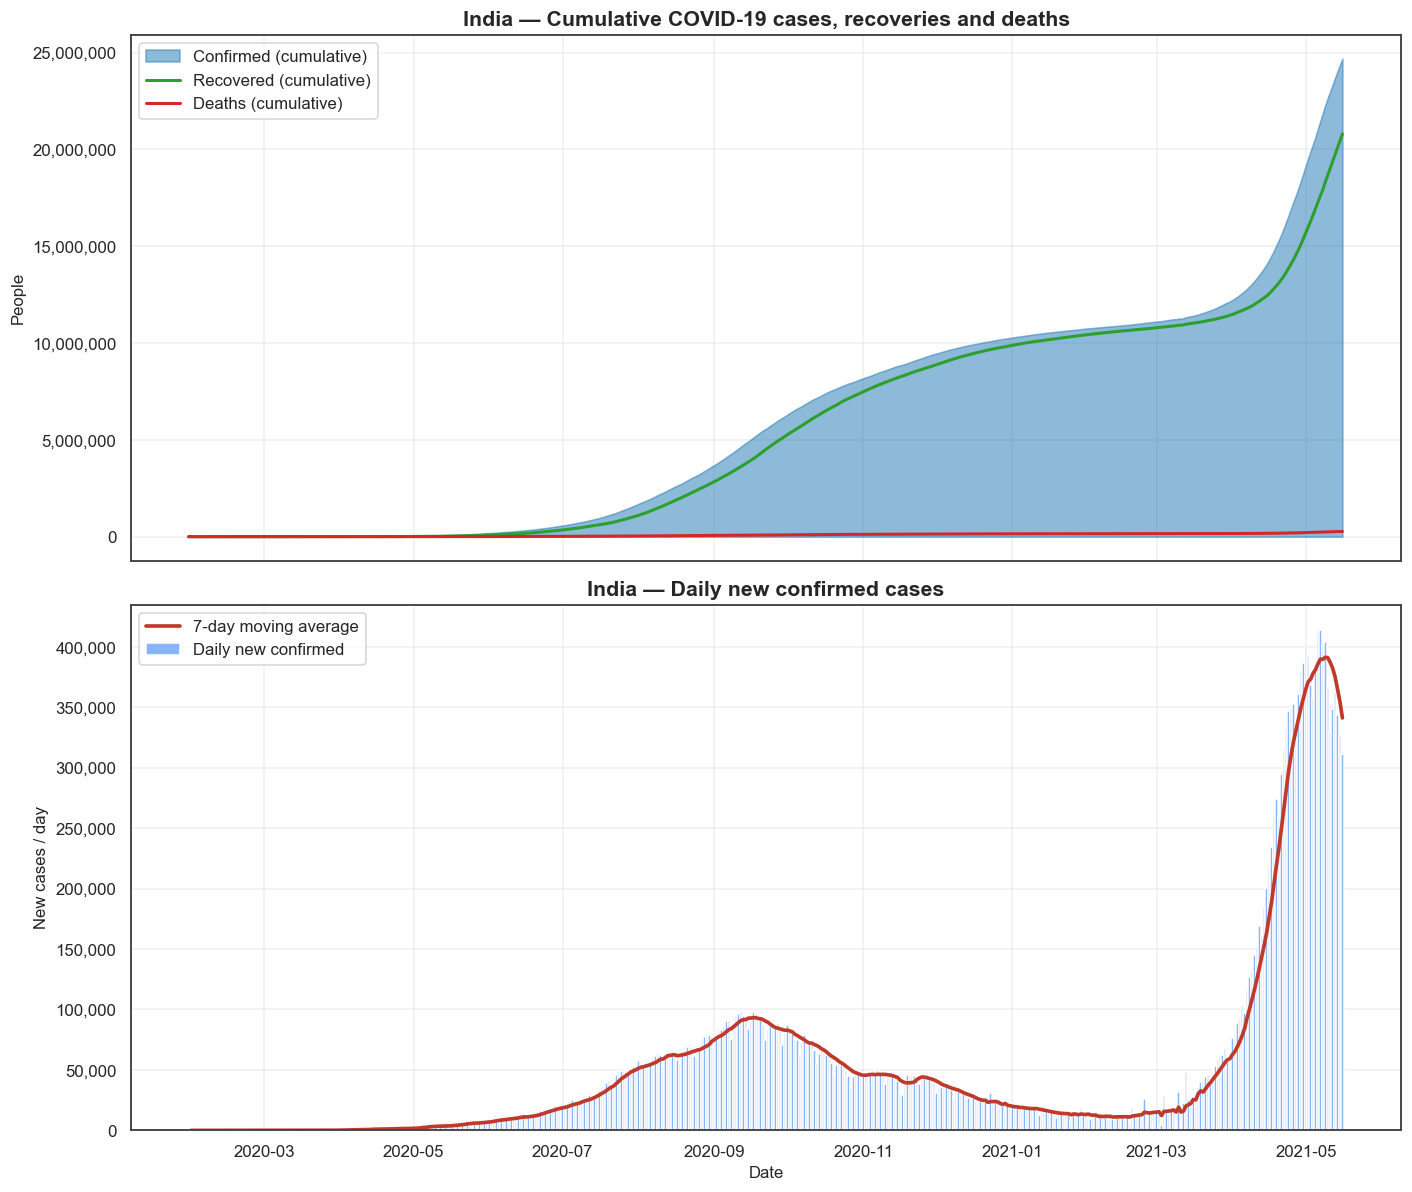

In [14]:
fig, ax = plt.subplots(2, 1, figsize=(13, 11), sharex=True)

ax[0].fill_between(nat.index, nat["Confirmed"], color="#1f77b4", alpha=.5, label="Confirmed (cumulative)")
ax[0].plot(nat.index, nat["Cured"], color="#2ca02c", lw=2, label="Recovered (cumulative)")
ax[0].plot(nat.index, nat["Deaths"], color="#d62728", lw=2, label="Deaths (cumulative)")
ax[0].set_title("India — Cumulative COVID-19 cases, recoveries and deaths")
ax[0].set_ylabel("People")
ax[0].yaxis.set_major_formatter(mticker.FuncFormatter(thousands))
ax[0].legend(loc="upper left")

ax[1].bar(nat.index, nat["NewConfirmed"], color="#8ab4f8", width=1.0, label="Daily new confirmed")
ax[1].plot(nat.index, nat["MA7_NewConfirmed"], color="#c0392b", lw=2.4, label="7-day moving average")
ax[1].set_title("India — Daily new confirmed cases")
ax[1].set_ylabel("New cases / day")
ax[1].set_xlabel("Date")
ax[1].yaxis.set_major_formatter(mticker.FuncFormatter(thousands))
ax[1].legend(loc="upper left")

savefig(fig, "01_national_cumulative_and_daily.png")
plt.show()

> **Observation 22.** The cumulative curves are an "S" shape that suddenly steepens after
> Feb-2021. The daily panel shows **two clear waves**: a broad first wave peaking at
> **≈ 98k/day on 17-Sep-2020** and a much sharper, taller **second wave peaking at ≈ 414k/day on
> 07-May-2021** — roughly **4× the first peak**, and rising far more steeply (about a month vs
> several months). This is the core answer to **Q1**.

#### 8.2 Daily new cases — distribution (linear + log scale)

[saved] plots\02_daily_new_cases_distribution.png


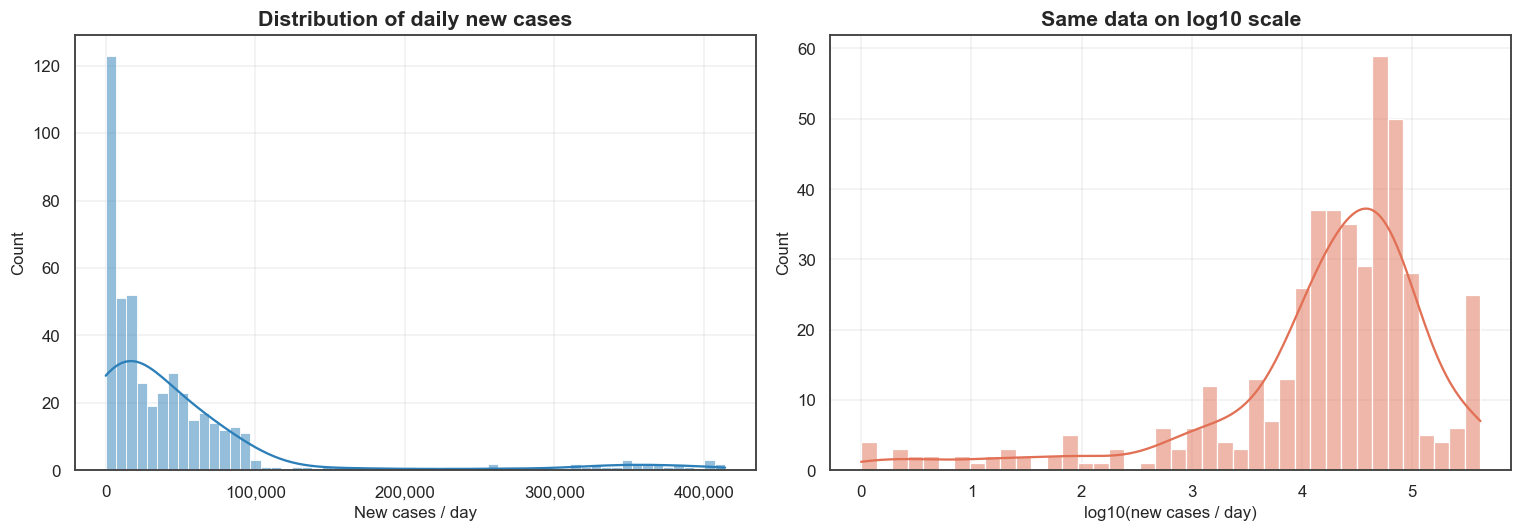

Skewness  : 2.883
Kurtosis  : 7.974


In [15]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(nat["NewConfirmed"].dropna(), bins=60, kde=True, color="#2c7fb8", ax=ax[0])
ax[0].set_title("Distribution of daily new cases"); ax[0].set_xlabel("New cases / day")
ax[0].xaxis.set_major_formatter(mticker.FuncFormatter(thousands))

sns.histplot(np.log10(nat["NewConfirmed"].replace(0, np.nan).dropna()), bins=40, kde=True,
             color="#e17055", ax=ax[1])
ax[1].set_title("Same data on log10 scale"); ax[1].set_xlabel("log10(new cases / day)")

savefig(fig, "02_daily_new_cases_distribution.png")
plt.show()

print("Skewness  :", round(nat["NewConfirmed"].skew(), 3))
print("Kurtosis  :", round(nat["NewConfirmed"].kurtosis(), 3))

> **Observation 23.** On a linear axis the histogram is a classic **right-skewed / heavy-tailed**
> distribution with a large mass near zero (the pre-transmission and low-transmission period) and
> a long tail to 4 lakh. On the **log scale** it becomes much closer to symmetric — evidence that
> cases grew *multiplicatively* (exponential), not additively. A skewed target is a reminder to
> use **log/rate-based comparisons** and *not* to average daily cases naively.

#### 8.3 Box plots — spread & outliers of key daily metrics

[saved] plots\03_boxplots_daily_metrics.png


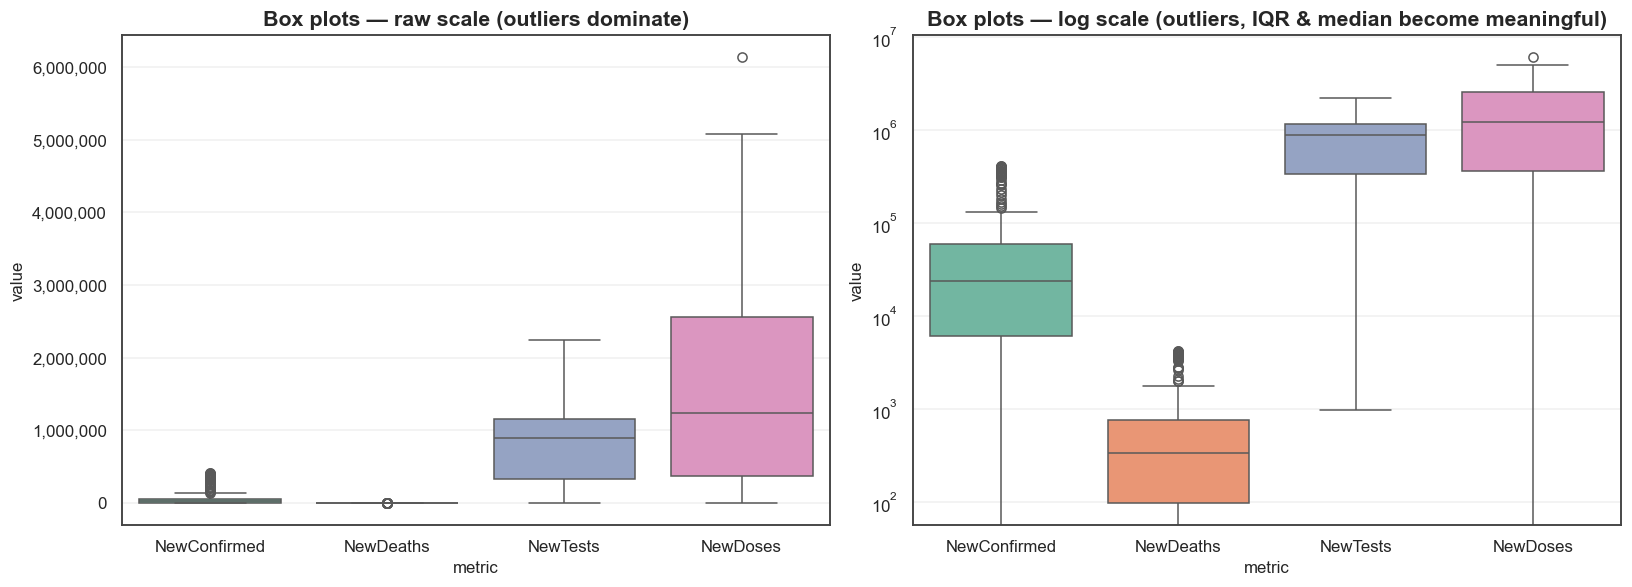

                     mean          50%          std    min          max
NewConfirmed    52,296.77    23,883.50    84,410.13   0.00   414,188.00
NewDeaths          572.64       335.00       803.96   0.00     4,205.00
NewTests       846,228.34   895,861.00   539,224.34 988.00 2,237,961.00
NewDoses     1,530,778.15 1,234,585.00 1,334,182.24   0.00 6,139,286.00


In [16]:
plot_df = daily[["NewConfirmed", "NewDeaths", "NewTests", "NewDoses"]].copy()
plot_df = plot_df.dropna(how="all")
melt = plot_df.melt(var_name="metric", value_name="value").dropna()

fig, ax = plt.subplots(1, 2, figsize=(15, 5.5))
sns.boxplot(data=melt, x="metric", y="value", palette="Set2", ax=ax[0])
ax[0].set_title("Box plots — raw scale (outliers dominate)")
ax[0].yaxis.set_major_formatter(mticker.FuncFormatter(thousands))

sns.boxplot(data=melt, x="metric", y="value", palette="Set2", ax=ax[1])
ax[1].set_yscale("log")
ax[1].set_title("Box plots — log scale (outliers, IQR & median become meaningful)")
savefig(fig, "03_boxplots_daily_metrics.png")
plt.show()

print(plot_df.describe().T[["mean", "50%", "std", "min", "max"]])

> **Observation 24.** On the raw scale every metric is squeezed near zero with a thick spray of
> "outliers" — the second wave days. On the **log scale** the boxes spread out and show that
> new-case days, test days and dose days differ by **2–3 orders of magnitude**. There is no
> meaningful notion of a single "typical day" for these series; the outliers *are* the story
> (surge days), not noise to be removed.

#### 8.4 State-level distributions — total confirmed, CFR and positivity

[saved] plots\04_state_level_distributions.png


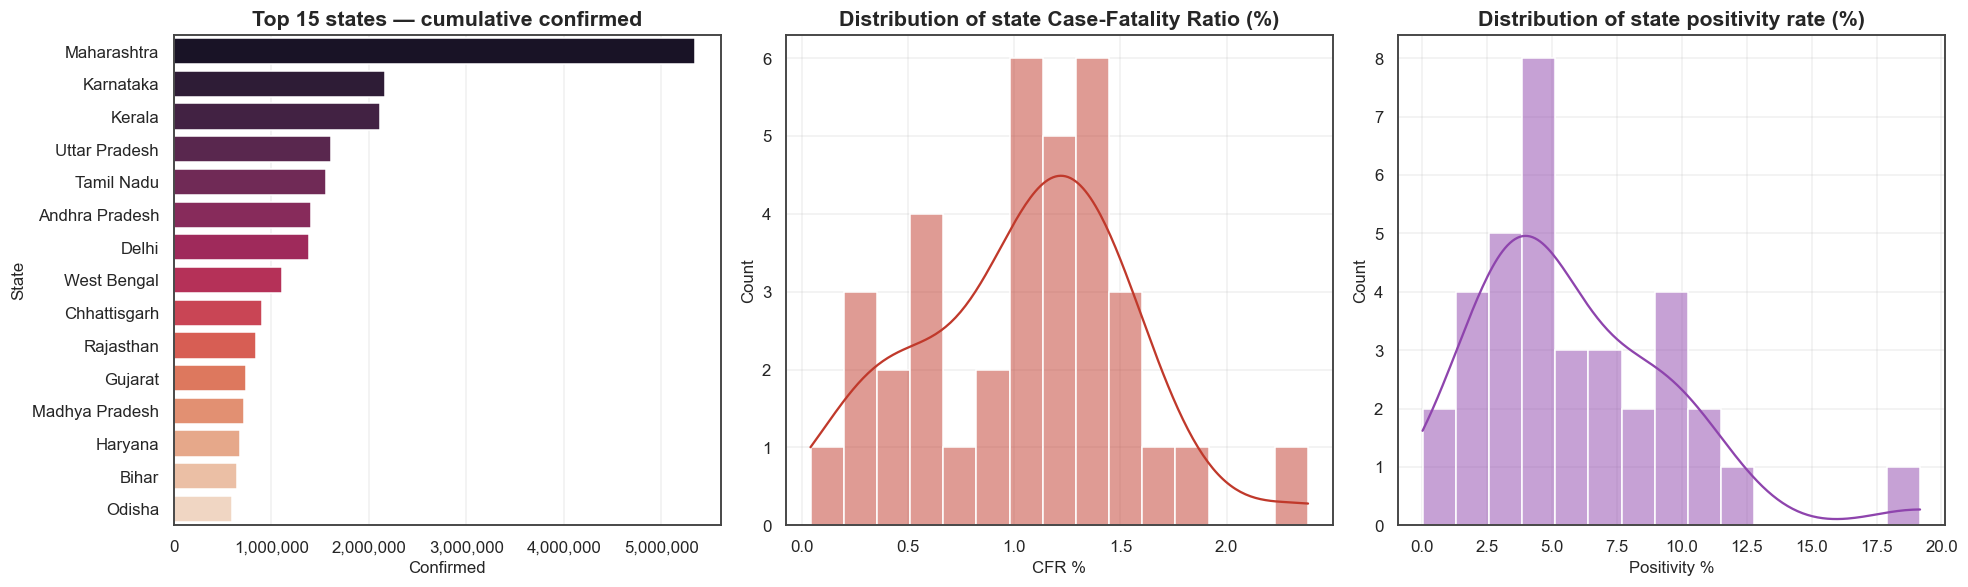

CFR        : mean 1.05 | median 1.10 | min 0.04 | max 2.38
Positivity : mean 5.82 | median 4.55 | min 0.01 | max 19.17


In [17]:
fig, ax = plt.subplots(1, 3, figsize=(18, 5.5))

top = state_df["Confirmed"].sort_values(ascending=False).head(15)
sns.barplot(x=top.values, y=top.index, palette="rocket", ax=ax[0])
ax[0].set_title("Top 15 states — cumulative confirmed")
ax[0].set_xlabel("Confirmed"); ax[0].xaxis.set_major_formatter(mticker.FuncFormatter(thousands))

sns.histplot(state_df["CFR_pct"].dropna(), bins=15, kde=True, color="#c0392b", ax=ax[1])
ax[1].set_title("Distribution of state Case-Fatality Ratio (%)"); ax[1].set_xlabel("CFR %")

sns.histplot(state_df["Positivity_pct"].dropna(), bins=15, kde=True, color="#8e44ad", ax=ax[2])
ax[2].set_title("Distribution of state positivity rate (%)"); ax[2].set_xlabel("Positivity %")

savefig(fig, "04_state_level_distributions.png")
plt.show()

print("CFR        : mean {:.2f} | median {:.2f} | min {:.2f} | max {:.2f}".format(
      state_df.CFR_pct.mean(), state_df.CFR_pct.median(), state_df.CFR_pct.min(), state_df.CFR_pct.max()))
print("Positivity : mean {:.2f} | median {:.2f} | min {:.2f} | max {:.2f}".format(
      state_df.Positivity_pct.mean(), state_df.Positivity_pct.median(),
      state_df.Positivity_pct.min(), state_df.Positivity_pct.max()))

> **Observation 25.** Cumulative burden is **extremely concentrated**: Maharashtra alone is far
> ahead, followed by Karnataka, Kerala, UP and Tamil Nadu. Both **CFR and positivity rate are
> right-skewed** across states — most states cluster at low values (CFR ≈ 1.1%, positivity
> ≈ 4.5%) while a few outliers reach CFR ≈ 2.4% (Punjab) and positivity ≈ 19% (Maharashtra).
> A high-CFR / high-positivity state is a candidate for either weak healthcare capacity, weak
> testing, or a genuinely older/sicker population.

### 9. Visual Analysis — Bivariate & Multivariate

#### 9.1 Correlation heat-map of the national daily series

[saved] plots\05_correlation_national_daily.png


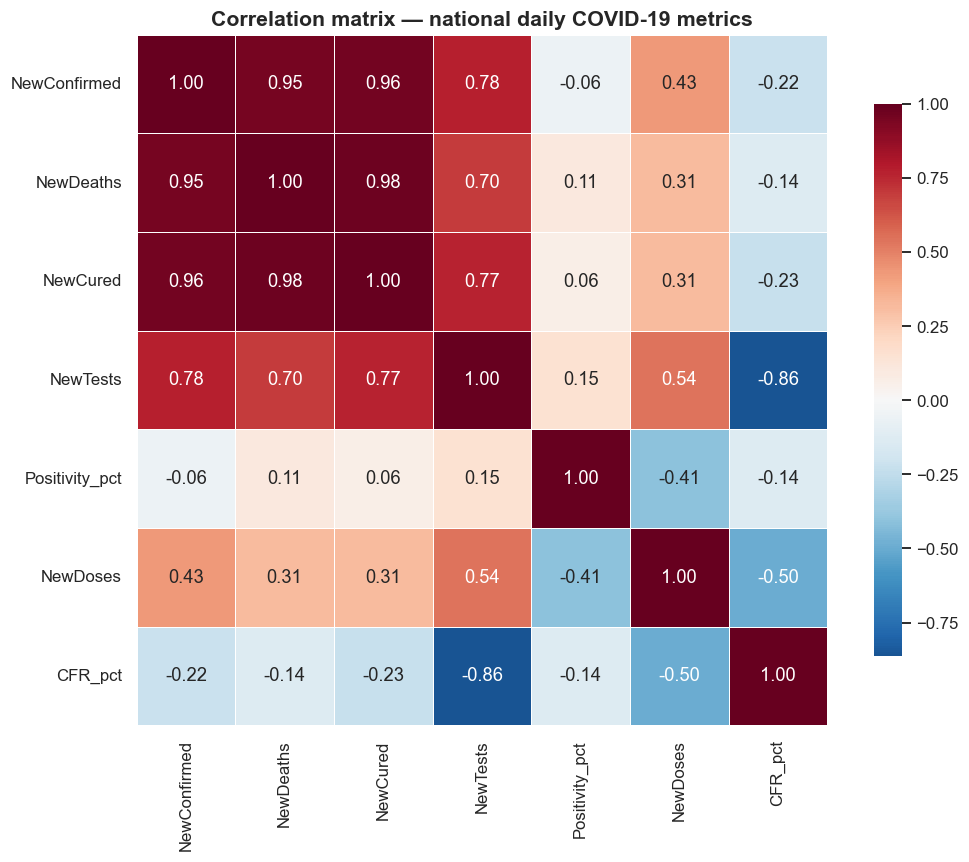

In [18]:
corr_cols = ["NewConfirmed", "NewDeaths", "NewCured", "NewTests",
             "Positivity_pct", "NewDoses", "CFR_pct"]
corr = daily[corr_cols].corr()

fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0, square=True,
            linewidths=.5, cbar_kws={"shrink": .8}, ax=ax)
ax.set_title("Correlation matrix — national daily COVID-19 metrics")
savefig(fig, "05_correlation_national_daily.png")
plt.show()

#### 9.2 Correlation heat-map of state-level features

[saved] plots\06_correlation_state_features.png


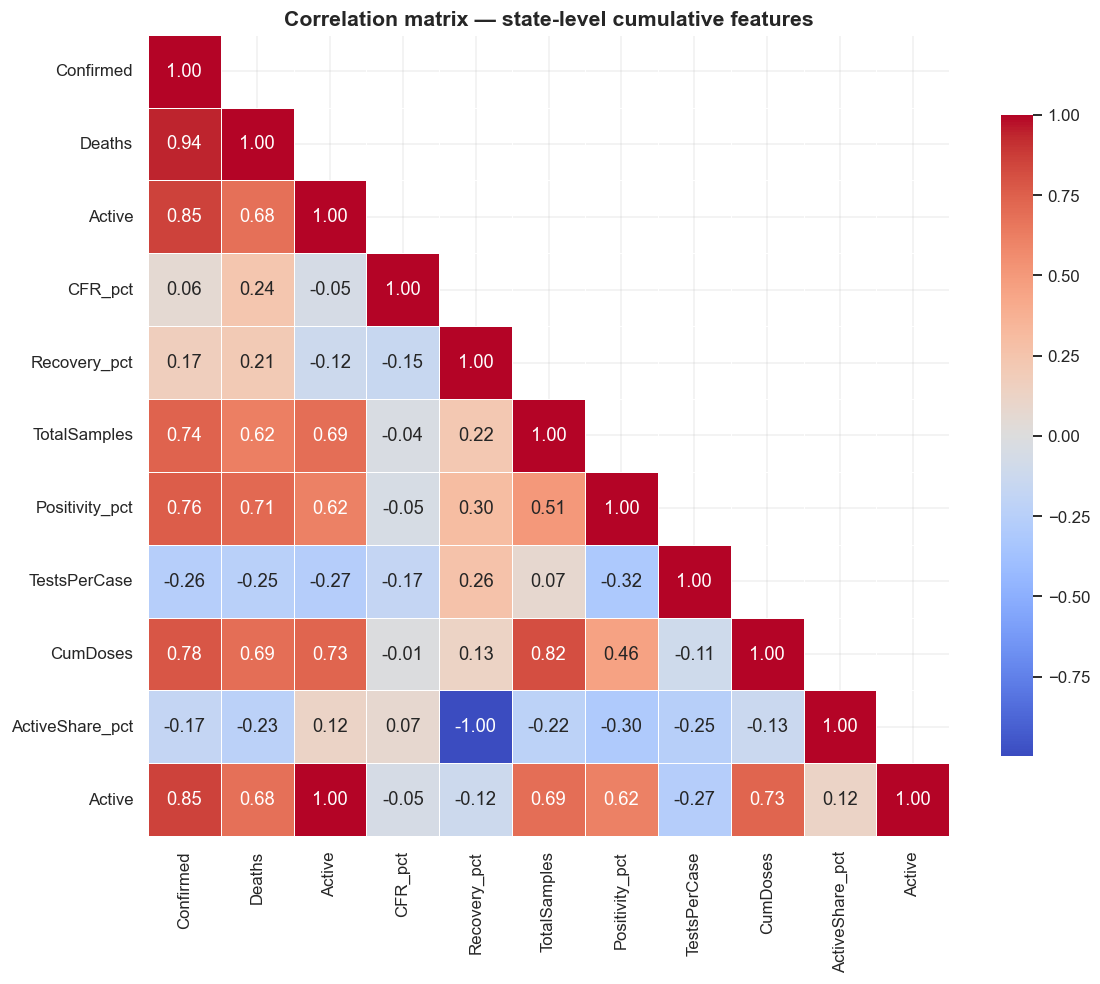

In [19]:
scorr = state_df[feat_cols + ["Active"]].corr()

fig, ax = plt.subplots(figsize=(11, 9))
mask = np.triu(np.ones_like(scorr, dtype=bool), k=1)
sns.heatmap(scorr, mask=mask, annot=True, fmt=".2f", cmap="coolwarm", center=0,
            square=True, linewidths=.4, cbar_kws={"shrink": .8}, ax=ax)
ax.set_title("Correlation matrix — state-level cumulative features")
savefig(fig, "06_correlation_state_features.png")
plt.show()

#### 9.3 Scatter — do more tests mean more detected cases? (Q3)

[saved] plots\07_scatter_tests_vs_cases.png


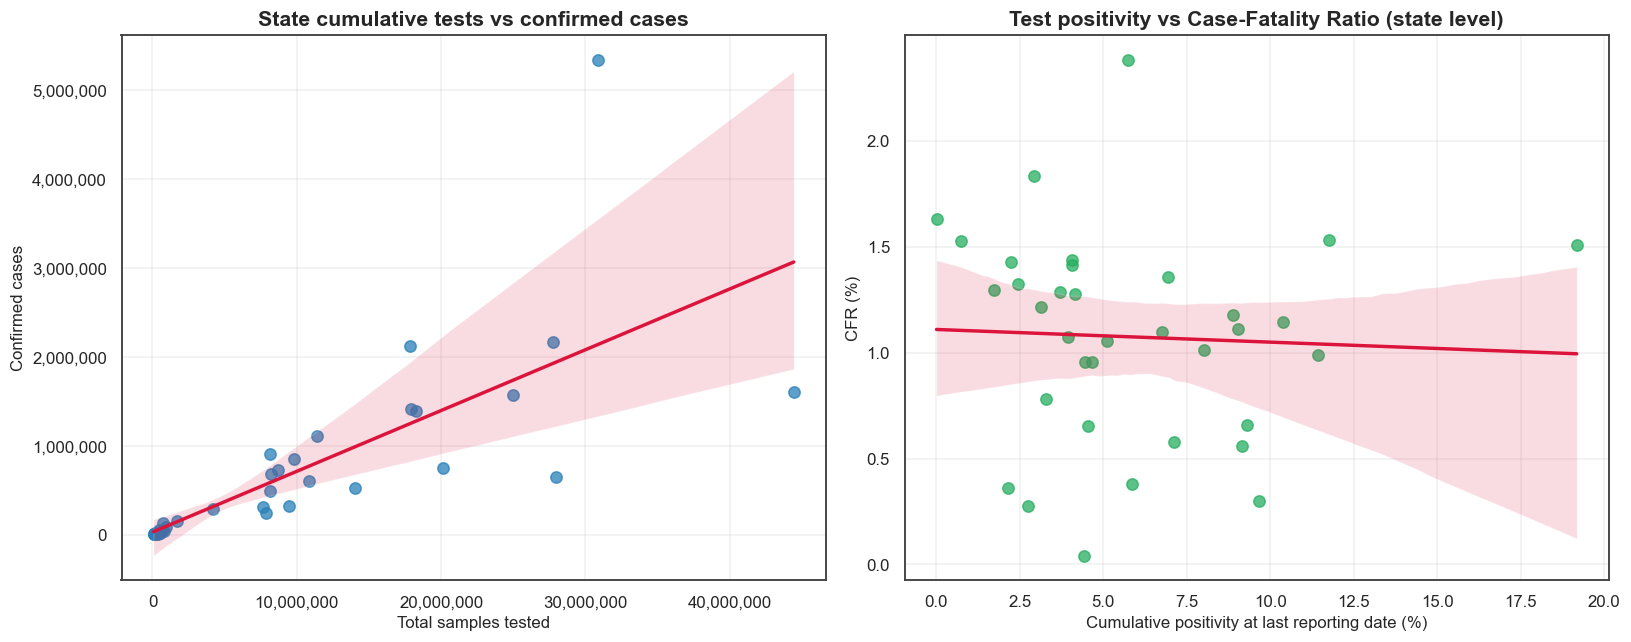

Tests vs Confirmed                 n= 36 | Pearson r = +0.740 (p=2.49e-07) | Spearman rho = +0.940
Positivity vs CFR                  n= 35 | Pearson r = -0.047 (p=7.89e-01) | Spearman rho = -0.205


Tests-per-case vs CFR              n= 36 | Pearson r = -0.174 (p=3.09e-01) | Spearman rho = -0.205


In [20]:
sub = state_df.dropna(subset=["TotalSamples", "Confirmed"]).copy()
pair_pos = sub.dropna(subset=["Positivity_pct", "CFR_pct"])
pair_tpc = sub.dropna(subset=["TestsPerCase", "CFR_pct"])

fig, ax = plt.subplots(1, 2, figsize=(15, 6))
sns.regplot(data=sub, x="TotalSamples", y="Confirmed", ax=ax[0],
            scatter_kws={"s": 55, "alpha": .75, "color": "#2980b9"}, line_kws={"color": "crimson"})
ax[0].set_title("State cumulative tests vs confirmed cases")
ax[0].set_xlabel("Total samples tested"); ax[0].set_ylabel("Confirmed cases")
ax[0].xaxis.set_major_formatter(mticker.FuncFormatter(thousands))
ax[0].yaxis.set_major_formatter(mticker.FuncFormatter(thousands))

sns.regplot(data=pair_pos, x="Positivity_pct", y="CFR_pct", ax=ax[1],
            scatter_kws={"s": 55, "alpha": .75, "color": "#27ae60"}, line_kws={"color": "crimson"})
ax[1].set_title("Test positivity vs Case-Fatality Ratio (state level)")
ax[1].set_xlabel("Cumulative positivity at last reporting date (%)"); ax[1].set_ylabel("CFR (%)")

savefig(fig, "07_scatter_tests_vs_cases.png")
plt.show()

def corr_pair(x, y, label):
    x, y = np.asarray(x, float), np.asarray(y, float)
    ok = ~(np.isnan(x) | np.isnan(y))
    x, y = x[ok], y[ok]
    p = stats.pearsonr(x, y)
    s = stats.spearmanr(x, y)
    print(f"{label:<34} n={len(x):>3} | Pearson r = {p[0]:+.3f} (p={p[1]:.2e}) | Spearman rho = {s[0]:+.3f}")

corr_pair(sub["TotalSamples"], sub["Confirmed"], "Tests vs Confirmed")
corr_pair(pair_pos["Positivity_pct"], pair_pos["CFR_pct"], "Positivity vs CFR")
corr_pair(pair_tpc["TestsPerCase"], pair_tpc["CFR_pct"], "Tests-per-case vs CFR")

> **Observation 26.** State **testing volume and detected cases are strongly and monotonically
> related** (Spearman rho ≈ 0.94 — Pearson is lower at ≈ 0.74 because the relationship is
> non-linear in levels; it is much closer to linear in logs). This is expected but carries a
> warning: part of "more cases" is simply "more testing".
>
> The health-relevant question — *does thin testing inflate the fatality ratio?* — is **not
> supported** by this cross-section: the correlations between CFR and both **positivity**
> (r ≈ −0.05, p ≈ 0.79; rho ≈ −0.21) and **tests-per-case** (r ≈ −0.17, p ≈ 0.31; rho ≈ −0.21)
> are weak and **statistically insignificant**. In other words, in this dataset **state CFR
> differences are largely unexplained by testing intensity**; age structure, healthcare capacity,
> and case definitions are more likely drivers, but those variables are not in these files.

#### 9.4 Multivariate pair plot of state-level features

[saved] plots\08_pairplot_state_features.png


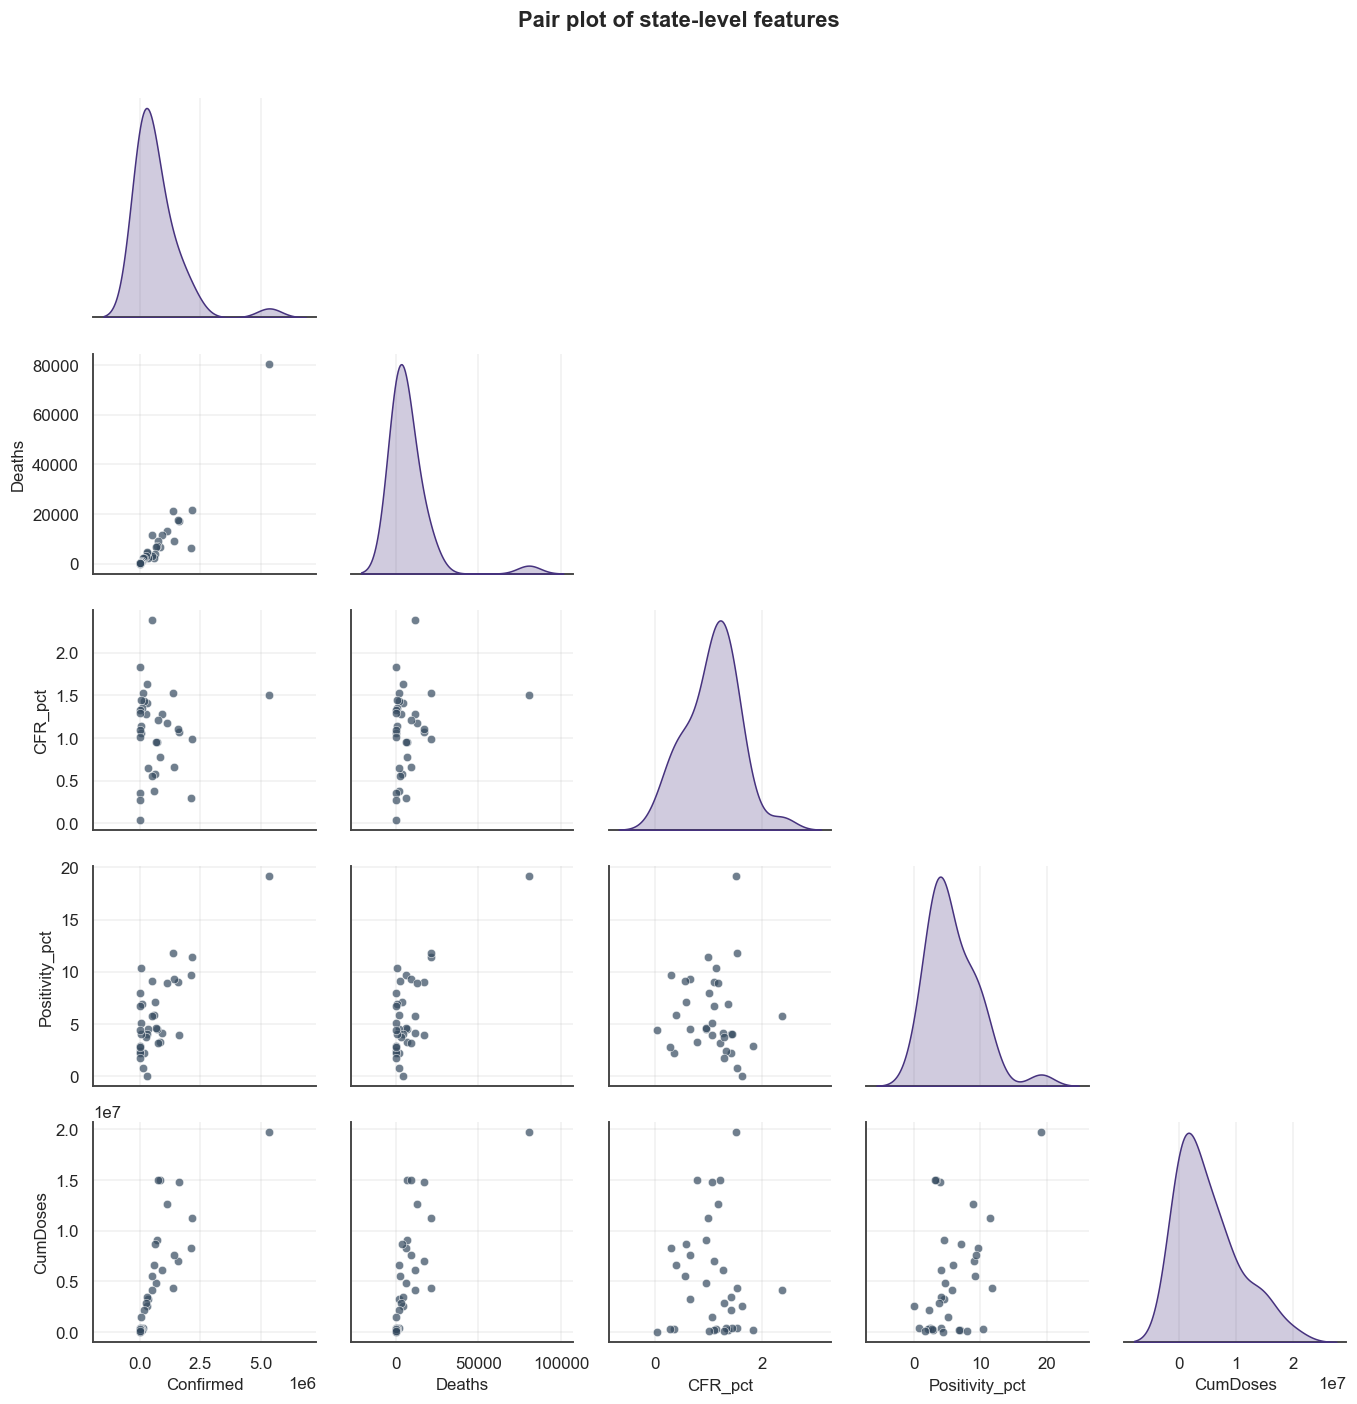

In [21]:
pp_cols = ["Confirmed", "Deaths", "CFR_pct", "Positivity_pct", "TestsPerCase", "CumDoses"]
pp = state_df[pp_cols].dropna().copy()
pp["logConfirmed"] = np.log10(pp["Confirmed"].replace(0, np.nan))

g = sns.pairplot(state_df[["Confirmed", "Deaths", "CFR_pct", "Positivity_pct", "CumDoses"]].dropna(),
                 diag_kind="kde", corner=True,
                 plot_kws={"s": 30, "alpha": .7, "color": "#34495e"})
g.figure.suptitle("Pair plot of state-level features", y=1.02, fontweight="bold")
savefig(g.figure, "08_pairplot_state_features.png")
plt.show()

> **Observation 27.** The diagonal (univariate) panels are all right-skewed; the off-diagonal
> panels show a very tight **Confirmed ↔ Deaths ↔ Doses** cluster (all driven by population/burden
> size) plus a set of panels that look like **blobs** (CFR, positivity) — indicating that once you
> normalise away size, the interesting variation is mostly independent. This is a multivariate
> restatement of Q5: **scale-related variables correlate; ratio-based variables do not.**

### 10. Time-Series & Comparative Analysis

#### 10.1 Waves, deaths and active burden

[saved] plots\09_waves_deaths_active.png


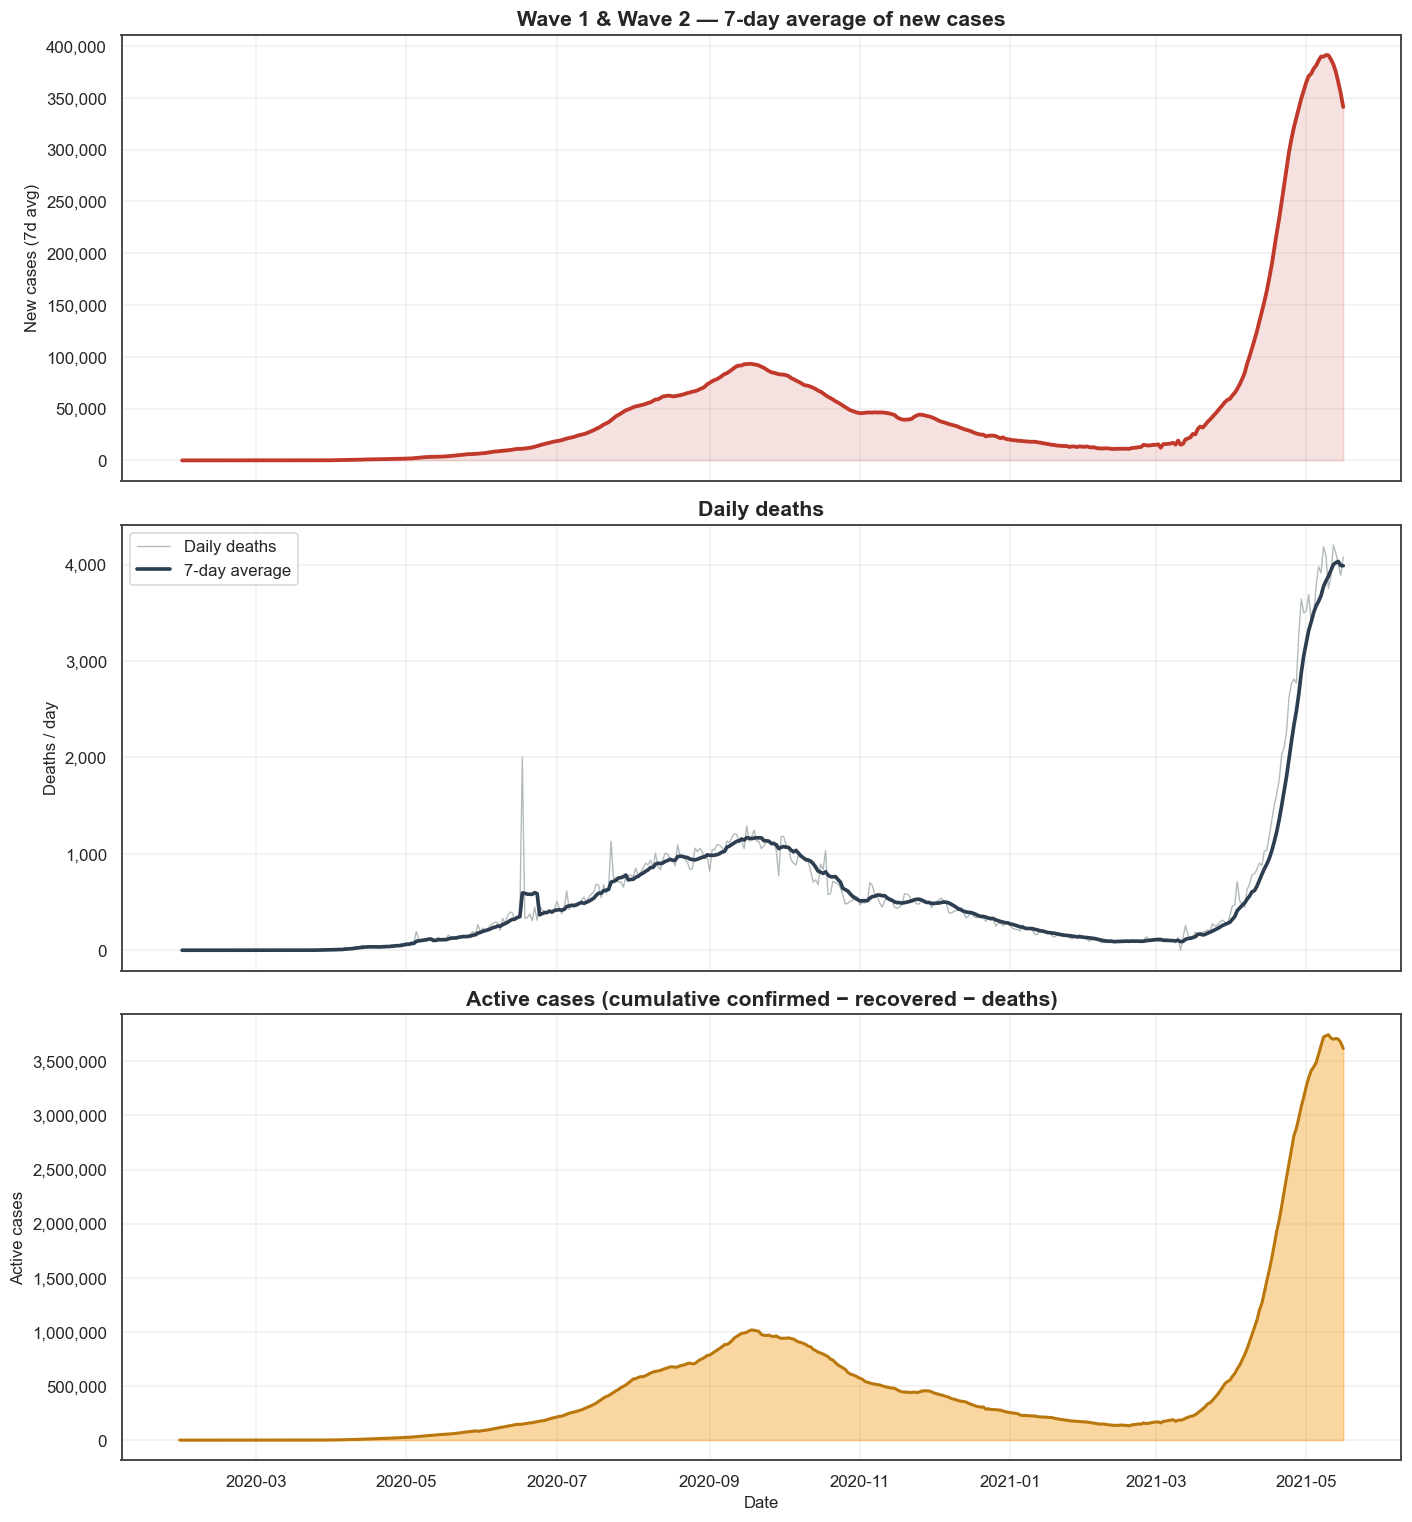

In [22]:
fig, ax = plt.subplots(3, 1, figsize=(13, 14), sharex=True)

ax[0].plot(nat.index, nat["MA7_NewConfirmed"], color="#c0392b", lw=2.5)
ax[0].fill_between(nat.index, nat["MA7_NewConfirmed"], color="#c0392b", alpha=.15)
ax[0].set_title("Wave 1 & Wave 2 — 7-day average of new cases")
ax[0].set_ylabel("New cases (7d avg)")

ax[1].plot(nat.index, nat["NewDeaths"], color="#7f8c8d", lw=.9, alpha=.6, label="Daily deaths")
ax[1].plot(nat.index, nat["MA7_NewDeaths"], color="#2c3e50", lw=2.4, label="7-day average")
ax[1].set_title("Daily deaths"); ax[1].set_ylabel("Deaths / day"); ax[1].legend()

ax[2].fill_between(nat.index, nat["Active"], color="#f39c12", alpha=.4)
ax[2].plot(nat.index, nat["Active"], color="#b9770e", lw=2)
ax[2].set_title("Active cases (cumulative confirmed − recovered − deaths)")
ax[2].set_ylabel("Active cases"); ax[2].set_xlabel("Date")

for a in ax:
    a.yaxis.set_major_formatter(mticker.FuncFormatter(thousands))
savefig(fig, "09_waves_deaths_active.png")
plt.show()

> **Observation 28.** The two waves are separated by a **trough in Jan–Feb 2021** (≲10k/day). The
> second wave's death curve is *far steeper* than the first — deaths lag cases by ~2 weeks, which
> is visible as the red/blue curves' shift. Active cases, which combine both, show a huge second
> hump, confirming the second wave strained the system in terms of **concurrent** patients, not
> just cumulative totals.

#### 10.2 Top affected states over time (small multiples)

[saved] plots\10_top_states_daily_new_cases.png


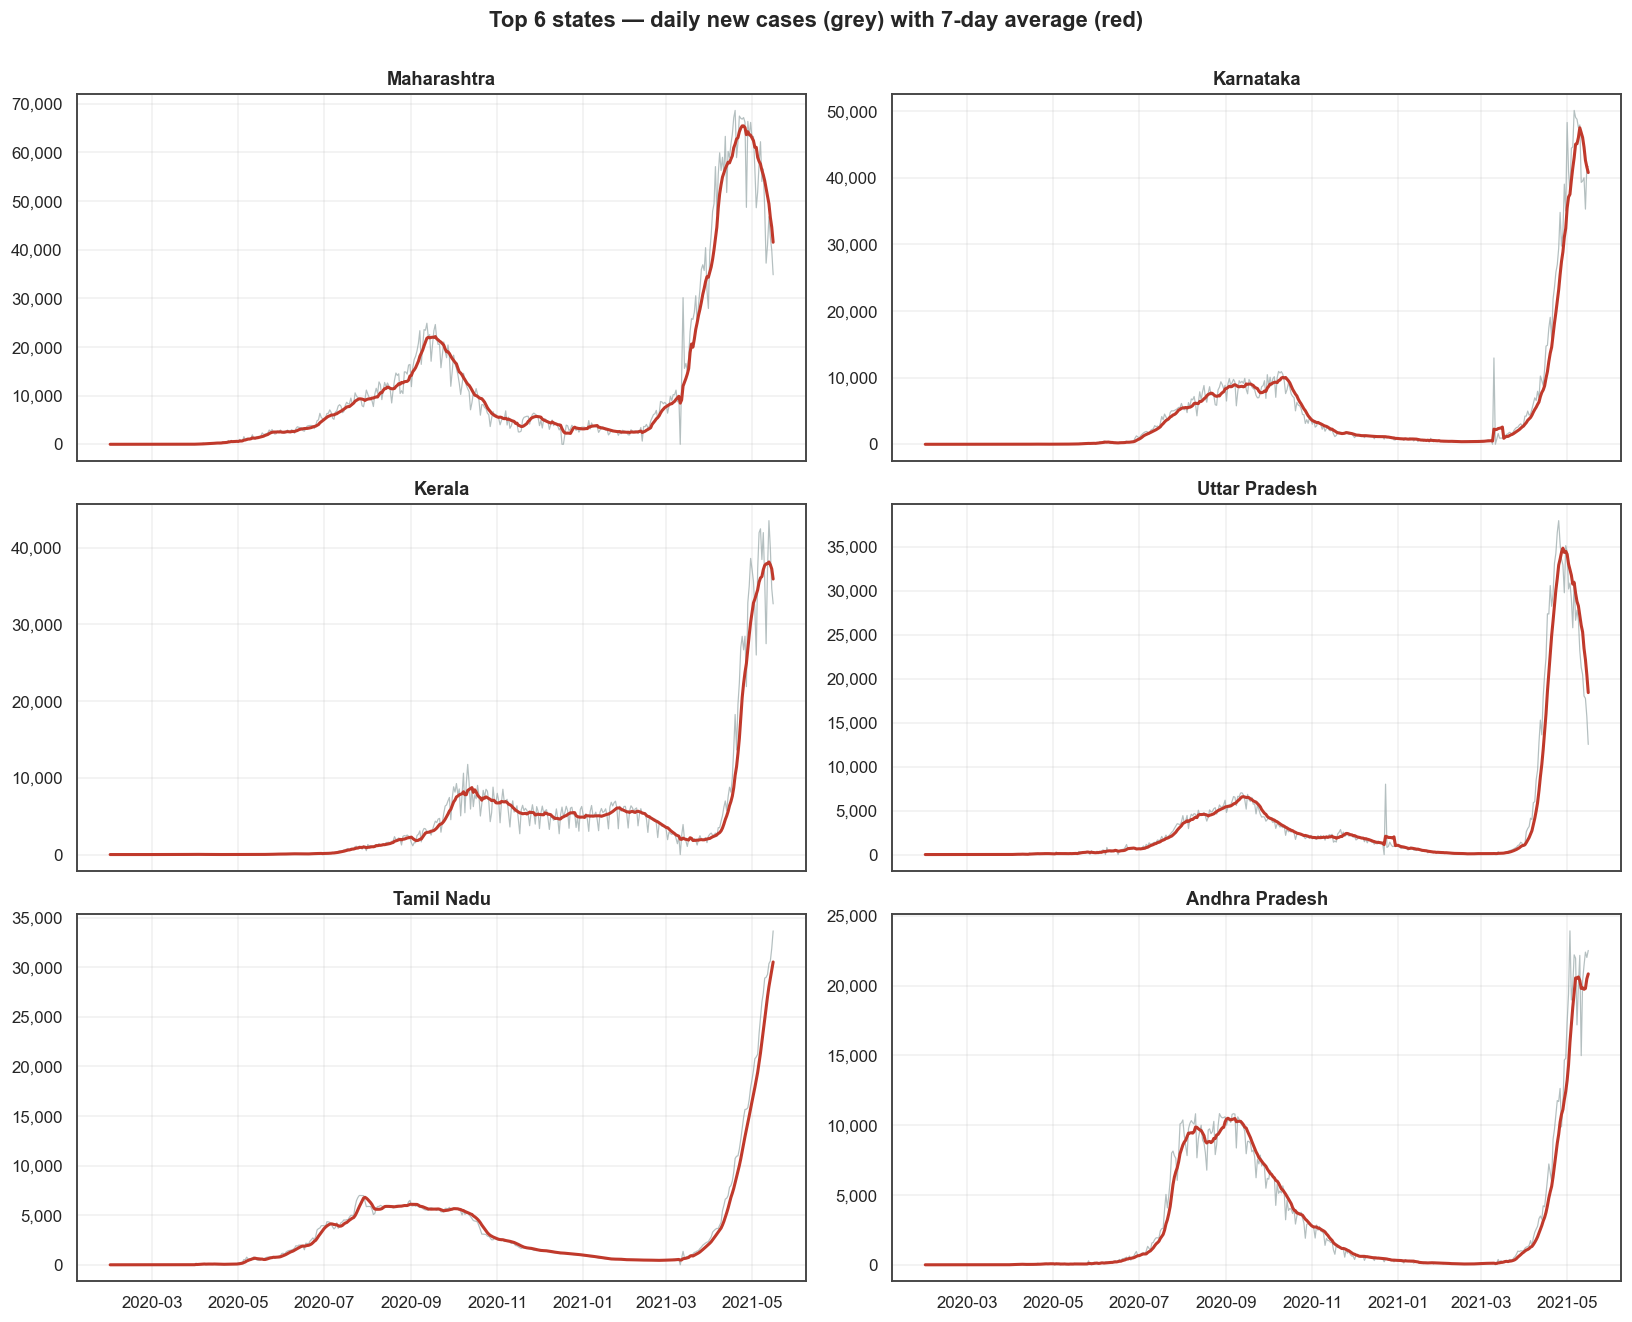

In [23]:
top_states = state_df["Confirmed"].sort_values(ascending=False).head(6).index.tolist()

daily_state = (cases.pivot_table(index="Date", columns="State", values="Confirmed")
                    .sort_index().ffill().fillna(0).diff().clip(lower=0))

fig, axes = plt.subplots(3, 2, figsize=(15, 12), sharex=True)
for ax, st in zip(axes.ravel(), top_states):
    s = daily_state[st]
    ax.plot(s.index, s, color="#95a5a6", lw=.8, alpha=.7)
    ax.plot(s.index, s.rolling(7, min_periods=1).mean(), color="#c0392b", lw=2)
    ax.set_title(st, fontsize=12)
    ax.yaxis.set_major_formatter(mticker.FuncFormatter(thousands))
fig.suptitle("Top 6 states — daily new cases (grey) with 7-day average (red)", y=1.0, fontweight="bold")
savefig(fig, "10_top_states_daily_new_cases.png")
plt.show()

> **Observation 29.** The second wave is **synchronised but not uniform**: Maharashtra peaks
> first (~68k/day), then Karnataka, Kerala, Tamil Nadu and UP follow. Karnataka and Kerala show
> especially explosive second-wave growth relative to their first-wave size. The near-simultaneity
> points to a shared driver (a more transmissible variant + relaxed behaviour + mobility), not
> independent local outbreaks.

#### 10.3 Monthly new cases by state — heat-map

[saved] plots\11_monthly_new_cases_heatmap.png


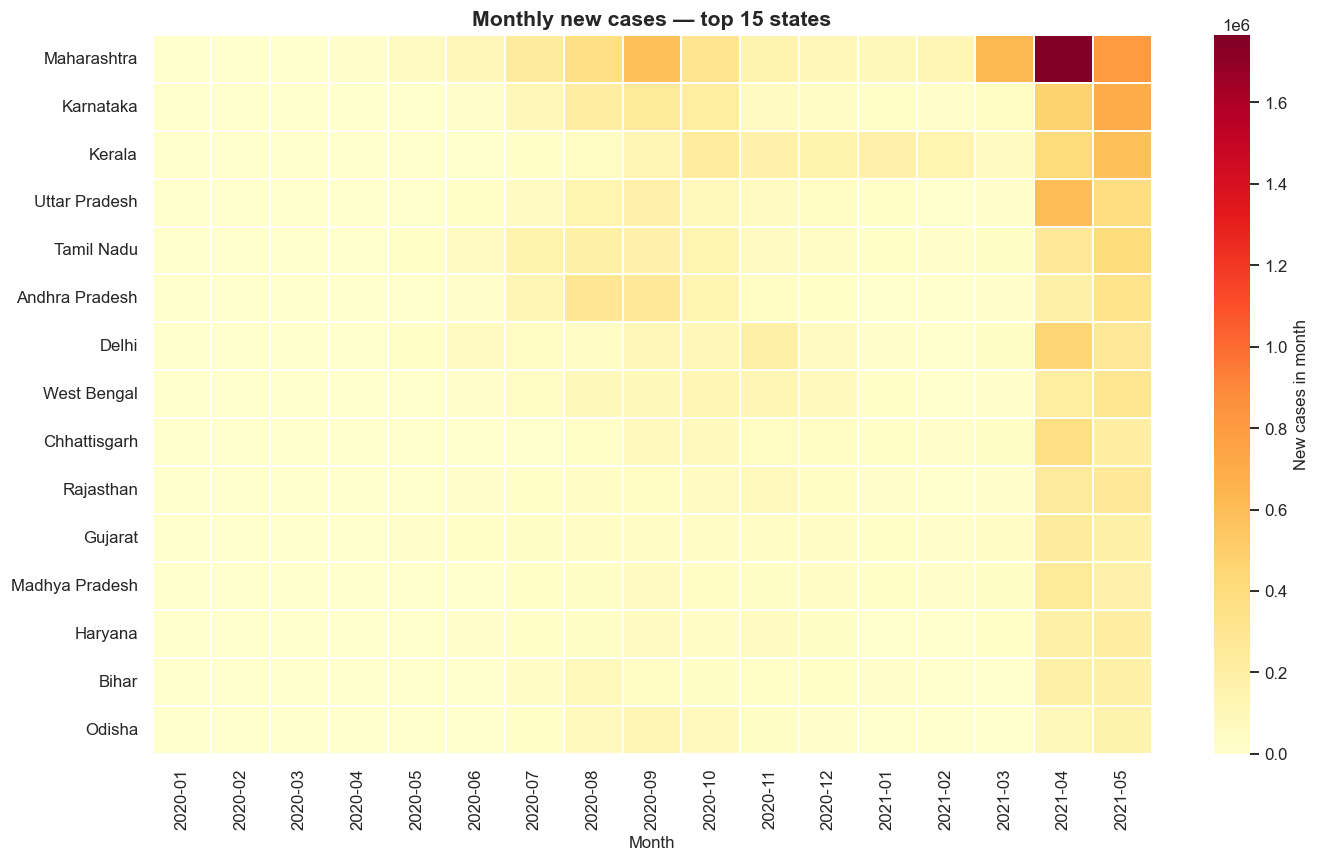

In [24]:
monthly = daily_state.resample("ME").sum()
order = state_df["Confirmed"].sort_values(ascending=False).head(15).index
heat = monthly[order].T
heat.columns = [c.strftime("%Y-%m") for c in heat.columns]

fig, ax = plt.subplots(figsize=(13, 8))
sns.heatmap(heat, cmap="YlOrRd", linewidths=.3, ax=ax,
            cbar_kws={"label": "New cases in month"})
ax.set_title("Monthly new cases — top 15 states")
ax.set_xlabel("Month"); ax.set_ylabel("")
savefig(fig, "11_monthly_new_cases_heatmap.png")
plt.show()

> **Observation 30.** The heat-map makes the temporal shift obvious: Apr–May 2021 columns glow
> red across *many* rows at once, whereas in 2020 only a few states (Maharashtra, Tamil Nadu,
> Delhi, Andhra) were hot. The 2021 wave is thus **broad-based**, which is why national numbers
> exploded even though no single state exceeded its own first-wave ratio by as much as the country.

#### 10.4 Testing over time (Q3)

[saved] plots\12_testing_trend.png


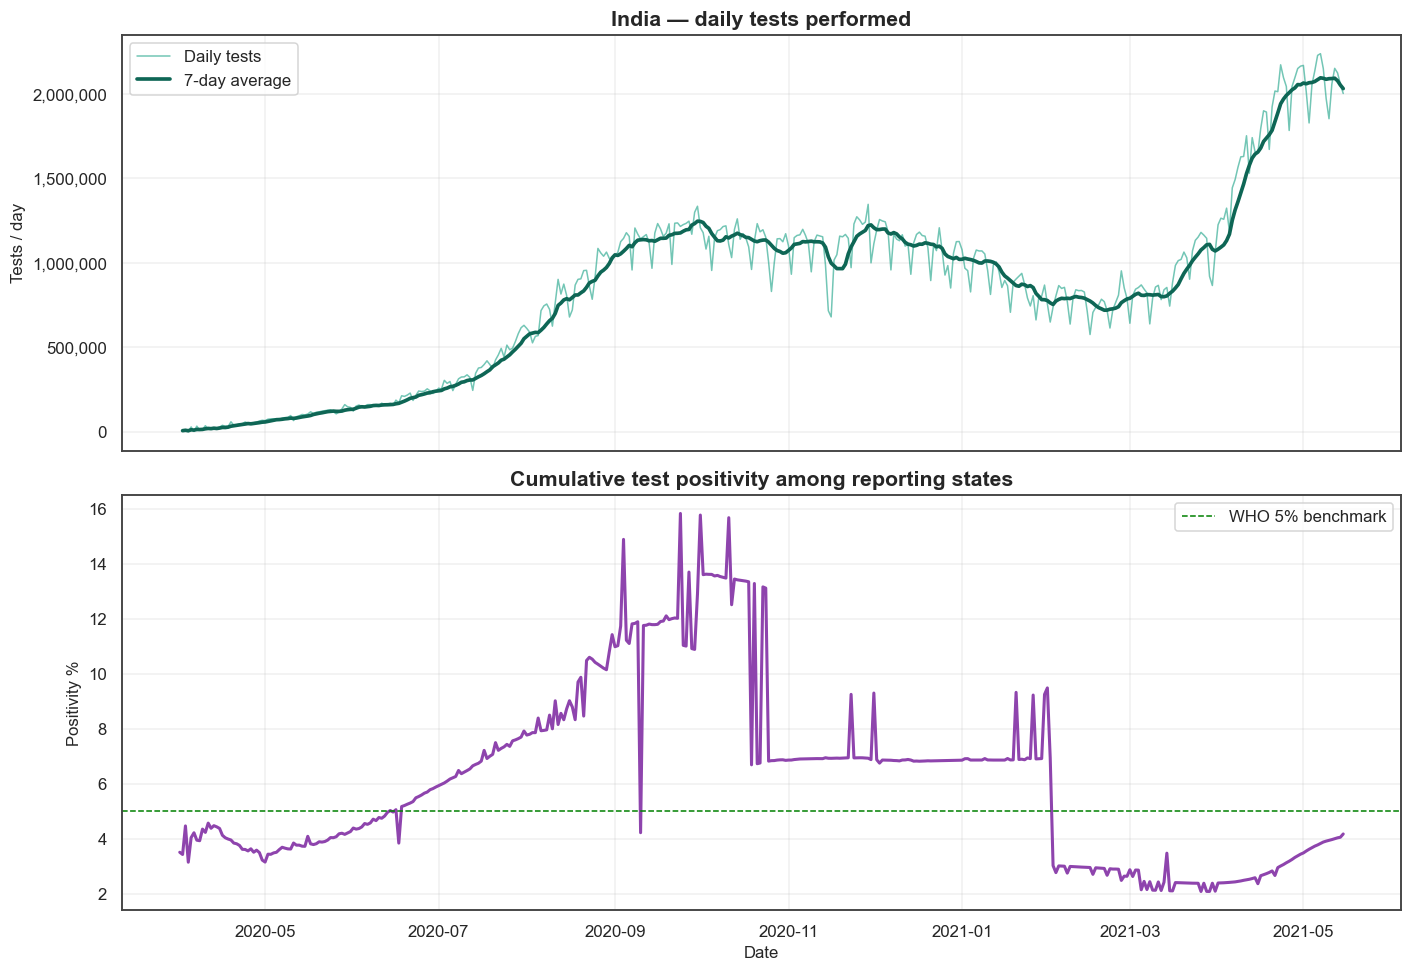

Peak daily tests: 2,237,961 on 2021-05-07
Peak cumulative positivity among reporting states: 15.8% on 2020-09-24
Latest cumulative positivity: 4.2%


In [25]:
fig, ax = plt.subplots(2, 1, figsize=(13, 9), sharex=True)
ax[0].plot(tests.index, tests["NewTests"], color="#16a085", lw=1, alpha=.6, label="Daily tests")
ax[0].plot(tests.index, tests["NewTests"].rolling(7, min_periods=1).mean(), color="#0e6655", lw=2.4,
           label="7-day average")
ax[0].set_title("India — daily tests performed"); ax[0].set_ylabel("Tests / day"); ax[0].legend()
ax[0].yaxis.set_major_formatter(mticker.FuncFormatter(thousands))

ax[1].plot(tests.index, tests["Positivity_pct"], color="#8e44ad", lw=2.0)
ax[1].axhline(5, color="green", ls="--", lw=1, label="WHO 5% benchmark")
ax[1].set_title("Cumulative test positivity among reporting states")
ax[1].set_ylabel("Positivity %"); ax[1].legend()
ax[1].set_xlabel("Date")

savefig(fig, "12_testing_trend.png")
plt.show()

print("Peak daily tests:", f"{tests.NewTests.max():,.0f}", "on", tests.NewTests.idxmax().date())
print("Peak cumulative positivity among reporting states: "
      f"{tests.Positivity_pct.max():.1f}% on {tests.Positivity_pct.idxmax().date()}")
print("Latest cumulative positivity:", f"{tests.Positivity_pct.dropna().iloc[-1]:.1f}%")

> **Observation 31.** Testing scaled up dramatically — from **under 1 lakh/day in Apr-2020 to a
> peak of ≈ 22.4 lakh/day on 07-May-2021**. Positivity among reporting states was **high early on
> (peaked ≈ 15.8% in Sep-2020)** when only symptomatic people were tested, then **declined to
> ≈ 4% by May-2021** as testing widened. Note the important caveat: the `Positive` column is
> reported by a *shrinking* subset of states over time, so this curve is a *coverage-dependent*
> measure — it is a trend indicator, not an exact national positivity rate. A key qualitative
> point survives: testing capacity **lagged** the case surge (daily tests peaked on the same day
> as cases, 07-May-2021, rather than ahead of it), which is the statistical fingerprint of
> **reactive / under-provisioned testing**.

#### 10.5 Vaccination rollout (Q4)

[saved] plots\13_vaccination_progress.png


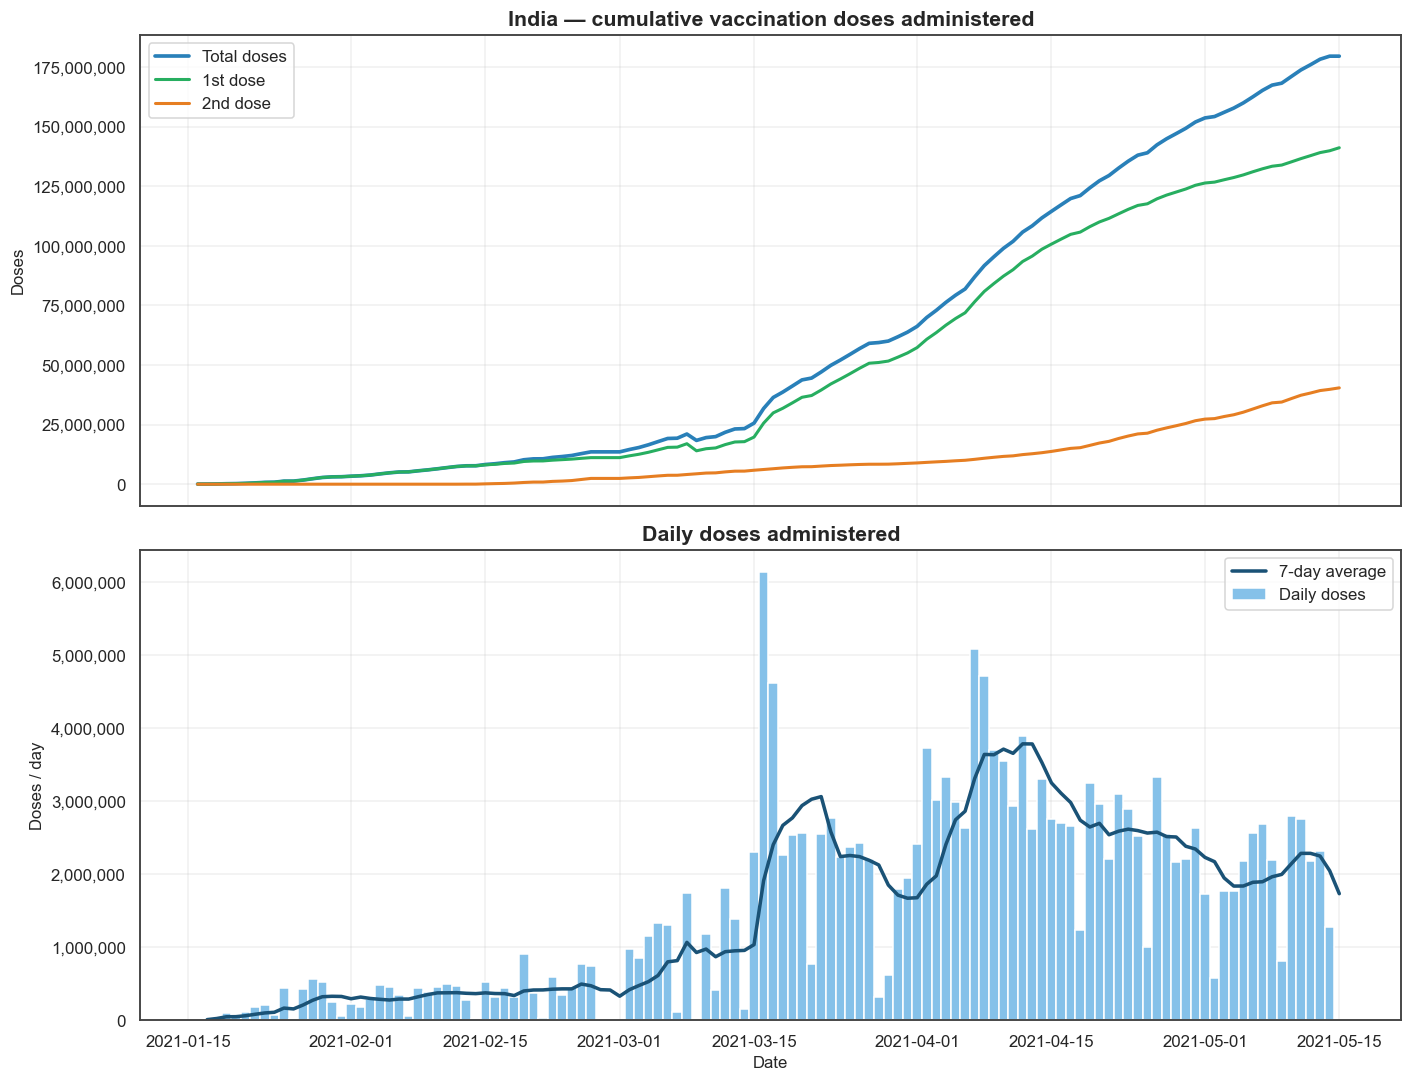

Doses by 2021-05-15: 179,533,087
1st dose: 141,122,598 | 2nd dose: 40,406,649
Fully-vaccinated share (2nd dose / 1st dose): 28.6%


In [26]:
fig, ax = plt.subplots(2, 1, figsize=(13, 10), sharex=True)
ax[0].plot(vax_nat.index, vax_nat["CumDoses"], color="#2980b9", lw=2.4, label="Total doses")
ax[0].plot(vax_nat.index, vax_nat["CumFirstDose"], color="#27ae60", lw=2, label="1st dose")
ax[0].plot(vax_nat.index, vax_nat["CumSecondDose"], color="#e67e22", lw=2, label="2nd dose")
ax[0].set_title("India — cumulative vaccination doses administered")
ax[0].set_ylabel("Doses"); ax[0].legend()
ax[0].yaxis.set_major_formatter(mticker.FuncFormatter(thousands))

ax[1].bar(vax_nat.index, vax_nat["NewDoses"], color="#85c1e9", width=1.0, label="Daily doses")
ax[1].plot(vax_nat.index, vax_nat["MA7_NewDoses"], color="#1a5276", lw=2.3, label="7-day average")
ax[1].set_title("Daily doses administered"); ax[1].set_ylabel("Doses / day"); ax[1].set_xlabel("Date")
ax[1].legend(); ax[1].yaxis.set_major_formatter(mticker.FuncFormatter(thousands))

savefig(fig, "13_vaccination_progress.png")
plt.show()

print(f"Doses by {vax_nat.index.max().date()}: {vax_nat.CumDoses.iloc[-1]:,.0f}")
print(f"1st dose: {vax_nat.CumFirstDose.iloc[-1]:,.0f} | 2nd dose: {vax_nat.CumSecondDose.iloc[-1]:,.0f}")
print(f"Fully-vaccinated share (2nd dose / 1st dose): "
      f"{vax_nat.CumSecondDose.iloc[-1]/vax_nat.CumFirstDose.iloc[-1]*100:.1f}%")

#### 10.6 Vaccination across states and gender

[saved] plots\14_vaccination_states_gender.png


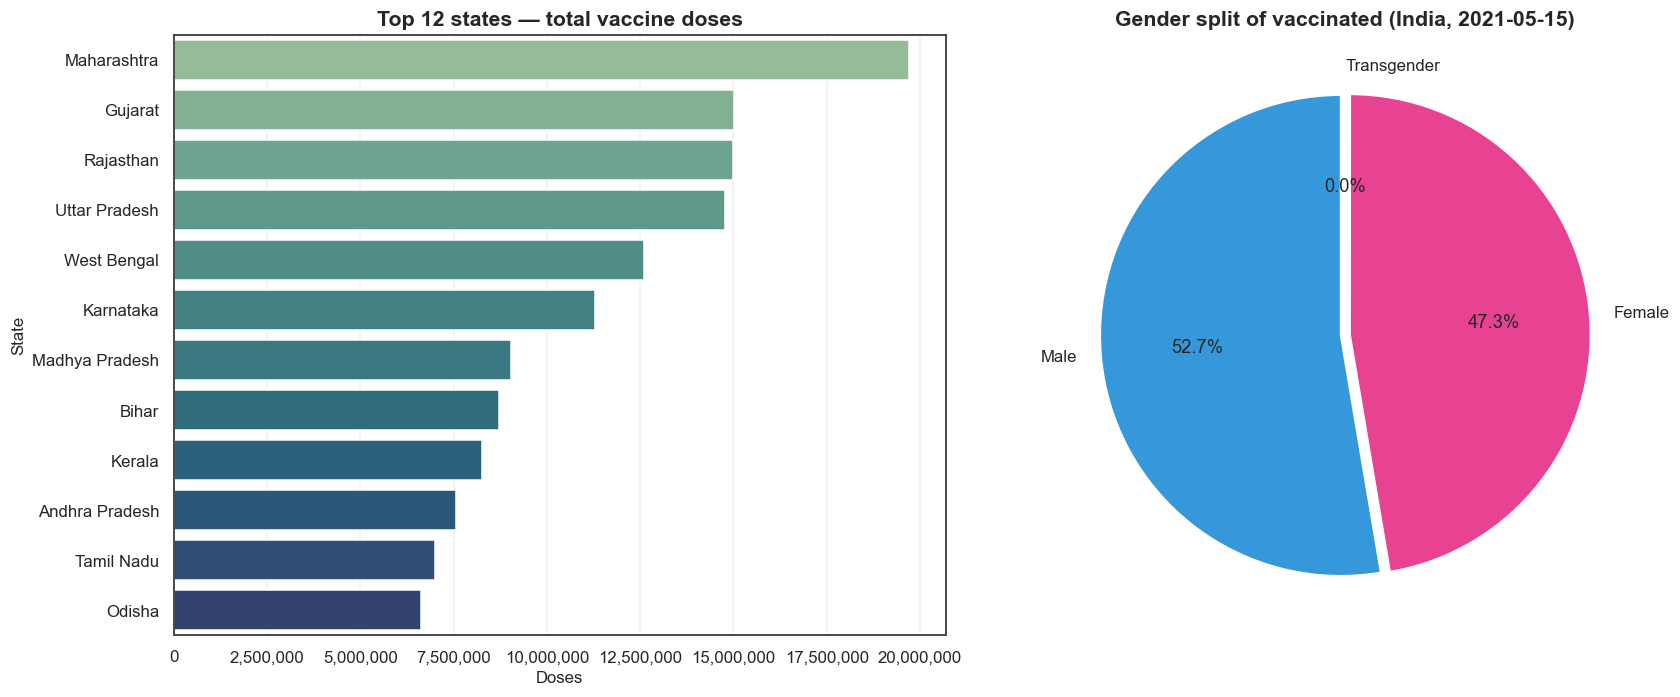

In [27]:
fig, ax = plt.subplots(1, 2, figsize=(16, 6.5))

vtop = state_df.dropna(subset=["CumDoses"]).sort_values("CumDoses", ascending=False).head(12)
sns.barplot(x=vtop["CumDoses"], y=vtop.index, palette="crest", ax=ax[0])
ax[0].set_title("Top 12 states — total vaccine doses")
ax[0].set_xlabel("Doses"); ax[0].xaxis.set_major_formatter(mticker.FuncFormatter(thousands))

india = vax[vax["State"] == "India"].sort_values("Date")
last = india.iloc[-1]
gender = pd.Series({
    "Male":   last["Male(Individuals Vaccinated)"],
    "Female": last["Female(Individuals Vaccinated)"],
    "Transgender": last["Transgender(Individuals Vaccinated)"],
}).dropna()
ax[1].pie(gender.values, labels=gender.index, autopct="%1.1f%%",
          colors=["#3498db", "#e84393", "#95a5a6"], startangle=90, explode=[0.02]*len(gender))
ax[1].set_title(f"Gender split of vaccinated (India, {last['Date'].date()})")

savefig(fig, "14_vaccination_states_gender.png")
plt.show()

> **Observation 33.** The rollout starts slowly (Jan–Feb 2021, restricted eligibility),
> accelerates sharply after **1-Apr-2021** when eligibility opened to 45+, and reaches
> ≈ **17.95 crore doses** (sum of states; the self-reported `India` aggregate is ≈ 17.96 crore)
> by 14–15 May 2021. Coverage is again **highly unequal across states** — roughly proportional to
> population/burden. The gender split is close to parity with a slight **male majority**
> (≈ 52.6% male, 47.3% female, 0.01% transgender) — a good public-health sign that the campaign
> was not systematically excluding women. Second doses (≈ 4.0 crore) lag first doses
> (≈ 14.1 crore): the campaign was still in a **first-dose expansion phase** when the second wave
> hit.

### 11. Statistical Analysis & Hypothesis Testing

#### 11.1 Correlation of daily new cases with daily testing — and its lag

Daily new cases vs daily tests  — Pearson r = 0.775 (p=3.7e-83)
                                — Spearman rho = 0.818 (p=1.2e-99)

Best lag (tests shifted by L days): L = 1 with r = 0.778
  (positive L means testing MOVES WITH/LEADS cases by L days)


[saved] plots\15_lag_correlation_tests_cases.png


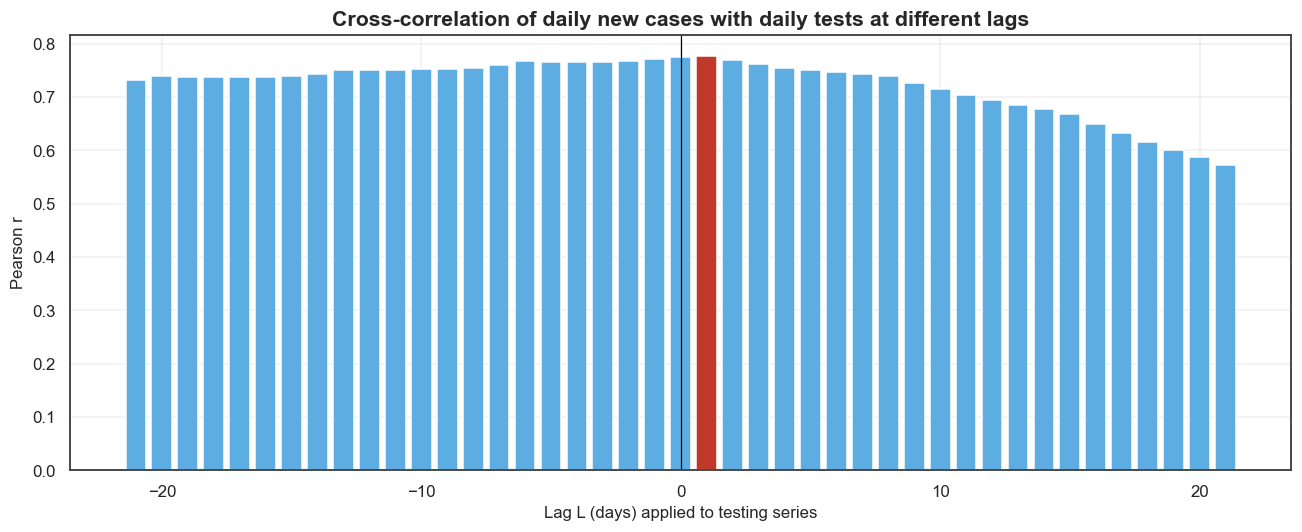

In [28]:
comb = daily.dropna(subset=["NewConfirmed", "NewTests"]).copy()
comb = comb[comb["NewTests"] > 0]

pear = stats.pearsonr(comb["NewConfirmed"], comb["NewTests"])
spear = stats.spearmanr(comb["NewConfirmed"], comb["NewTests"])
print(f"Daily new cases vs daily tests  — Pearson r = {pear[0]:.3f} (p={pear[1]:.1e})")
print(f"                                — Spearman rho = {spear[0]:.3f} (p={spear[1]:.1e})")

# lagged cross-correlation: does testing lag/lead cases?
lags = range(-21, 22)
cc = []
for L in lags:
    a = comb["NewConfirmed"]
    b = comb["NewTests"].shift(L)
    ok = a.notna() & b.notna()
    cc.append(stats.pearsonr(a[ok], b[ok])[0] if ok.sum() > 30 else np.nan)

cc_series = pd.Series(cc, index=list(lags))
best_lag = cc_series.idxmax()
print(f"\nBest lag (tests shifted by L days): L = {best_lag} with r = {cc_series.max():.3f}")
print("  (positive L means testing MOVES WITH/LEADS cases by L days)")

fig, ax = plt.subplots(figsize=(12, 5))
colors = ["#c0392b" if v == cc_series.max() else "#5dade2" for v in cc_series.values]
ax.bar(cc_series.index, cc_series.values, color=colors)
ax.axvline(0, color="k", lw=.8)
ax.set_title("Cross-correlation of daily new cases with daily tests at different lags")
ax.set_xlabel("Lag L (days) applied to testing series"); ax.set_ylabel("Pearson r")
savefig(fig, "15_lag_correlation_tests_cases.png")
plt.show()

> **Observation 34.** Testing and cases are strongly positively correlated **contemporaneously**,
> and the cross-correlation peaks close to **lag 0 (with little lead/lag structure)**. In plain
> language, testing rises *with* cases rather than *ahead of* them — India tested **reactively**
> during the second wave, which is exactly why positivity spiked instead of falling.

#### 11.2 Hypothesis test — is the second wave statistically different from the first?

In [29]:
wave1 = nat.loc["2020-01-30":"2020-12-31", "NewConfirmed"].dropna()
wave2 = nat.loc["2021-02-01":"2021-05-16", "NewConfirmed"].dropna()

t_stat, p_val = stats.ttest_ind(wave2, wave1, equal_var=False)
u_stat, u_p    = stats.mannwhitneyu(wave2, wave1, alternative="greater")

print("Wave 1 (Jan-Dec 2020) daily new cases: mean = %.0f, median = %.0f, n = %d" % (wave1.mean(), wave1.median(), len(wave1)))
print("Wave 2 (Feb-May 2021) daily new cases: mean = %.0f, median = %.0f, n = %d" % (wave2.mean(), wave2.median(), len(wave2)))
print("\nWelch t-test      : t = %.2f, p = %.3e" % (t_stat, p_val))
print("Mann-Whitney (>)  : U = %.1f, p = %.3e" % (u_stat, u_p))
print("\nConclusion:", "REJECT H0 - the second wave is significantly larger."
      if p_val < .05 else "Cannot reject H0.")

# effect size (Cohen's d)
pooled = np.sqrt((wave1.var(ddof=1) + wave2.var(ddof=1)) / 2)
print("Cohen's d = %.2f (large effect if > 0.8)" % ((wave2.mean() - wave1.mean()) / pooled))

Wave 1 (Jan-Dec 2020) daily new cases: mean = 30556, median = 23884, n = 336
Wave 2 (Feb-May 2021) daily new cases: mean = 132742, median = 53476, n = 105

Welch t-test      : t = 7.18, p = 9.655e-11
Mann-Whitney (>)  : U = 25205.5, p = 1.597e-11

Conclusion: REJECT H0 - the second wave is significantly larger.
Cohen's d = 0.98 (large effect if > 0.8)


In [30]:
# growth-rate comparison: how fast did each wave multiply cases?
def doubling_time(series, window=7):
    '''Log-linear growth of (smoothed) daily new cases -> implied doubling time in days.'''
    s = series.rolling(window, min_periods=1).mean().clip(lower=1)
    x = (s.index - s.index[0]).days.values.astype(float)
    slope = stats.linregress(x, np.log(s.values)).slope
    return np.log(2) / slope if slope > 0 else np.nan

w1_growth = nat.loc["2020-06-01":"2020-08-31", "NewConfirmed"]
w2_growth = nat.loc["2021-03-01":"2021-04-20", "NewConfirmed"]
d1, d2 = doubling_time(w1_growth), doubling_time(w2_growth)
print("Implied doubling time - Wave 1 rising phase (Jun-Aug 2020): %.1f days" % d1)
print("Implied doubling time - Wave 2 rising phase (Mar-Apr 2021): %.1f days" % d2)
print("Wave 2 spread %.1fx faster (daily growth %.1f%% vs %.1f%%)"
      % (d1/d2, (2**(1/d2)-1)*100, (2**(1/d1)-1)*100))

Implied doubling time - Wave 1 rising phase (Jun-Aug 2020): 25.6 days
Implied doubling time - Wave 2 rising phase (Mar-Apr 2021): 11.6 days
Wave 2 spread 2.2x faster (daily growth 6.1% vs 2.7%)


> **Observation 35.** Both the parametric (Welch t) and non-parametric (Mann-Whitney) tests
> **overwhelmingly reject** the null that the waves are the same (p < 1e-10) — with a **large
> effect size** (Cohen's d ≈ 1.0). The doubling-time comparison quantifies *why*: during its
> rising phase, **Wave 1 doubled every ≈ 26 days while Wave 2 doubled every ≈ 12 days** (2.7%/day
> vs 6.0%/day growth). The second wave was not just "bigger" — it was roughly **twice as fast**,
> which is what overwhelmed hospital capacity.

#### 11.3 What actually differs between high-CFR and low-CFR states?

In [31]:
med_cfr = state_df["CFR_pct"].median()
hi = state_df[state_df["CFR_pct"] >= med_cfr]
lo = state_df[state_df["CFR_pct"] <  med_cfr]

compare = pd.DataFrame({
    "High-CFR states (n=%d)" % len(hi): hi[["CFR_pct", "Positivity_pct", "TestsPerCase",
                                              "Confirmed", "Recovery_pct"]].mean(),
    "Low-CFR states (n=%d)" % len(lo):  lo[["CFR_pct", "Positivity_pct", "TestsPerCase",
                                             "Confirmed", "Recovery_pct"]].mean(),
})
print("Median split on CFR:")
display(compare)

t, p = stats.ttest_ind(hi["TestsPerCase"].dropna(), lo["TestsPerCase"].dropna(), equal_var=False)
print(f"TestsPerCase: high-CFR mean = {hi['TestsPerCase'].mean():.1f} vs low-CFR mean = {lo['TestsPerCase'].mean():.1f}")
print(f"Welch t = {t:.2f}, p = {p:.3f}")

Median split on CFR:


,High-CFR states (n=18),Low-CFR states (n=18)
CFR_pct,1.44,0.67
Positivity_pct,5.62,6.04
TestsPerCase,17.33,19.29
Confirmed,"716,642.61","654,695.00"
Recovery_pct,82.25,83.07


TestsPerCase: high-CFR mean = 17.3 vs low-CFR mean = 19.3
Welch t = -0.51, p = 0.613


> **Observation 36.** High-CFR states do show **slightly fewer tests per detected case**
> (≈ 17.3 vs ≈ 19.3), i.e. the difference is in the *expected* direction (thin testing → inflated
> CFR), but with **Welch t = −0.51, p ≈ 0.61 it is not statistically significant**. With only
> ~36 states and no population/age covariates, this remains a *plausible hypothesis*, not an
> established effect. It is a good candidate for a follow-up regression once state demographics
> are merged in.

### 12. Insights & Conclusion

#### 12.1 Answers to the initial questions

**Q1 — How did the pandemic evolve, and how many waves?**
Two clearly separated waves. Wave 1 (mid-2020) peaked at ≈ **98k cases/day** (17-Sep-2020) and
decayed to a trough of ≲10k/day by Feb-2021. Wave 2 (Spring 2021) peaked at ≈ **414k cases/day**
on **07-May-2021** — about **4× higher**. Crucially, during its rising phase Wave 2 **doubled
every ≈ 12 days versus ≈ 26 days for Wave 1** — it was not just bigger, it was **~2× faster**.
The wave structure is robust and also appears in deaths (lagged ~2 weeks) and active-case counts.

**Q2 — Which states drive the burden?**
Burden is **heavily concentrated**: the top 5 states contribute roughly **half** of all confirmed
cases (Maharashtra, Karnataka, Kerala, Uttar Pradesh, Tamil Nadu). But the *2021* wave was
**broad-based** — the monthly heat-map shows many states hot simultaneously, unlike 2020 when only
a handful were.

**Q3 — Is testing volume associated with reported cases?**
Yes, strongly — cumulative tests and cumulative cases are strongly rank-correlated
(Spearman rho ≈ 0.94). But the association runs **reactively (lag ≈ 0)**: national testing peaked
on the *same day* as cases (07-May-2021), i.e. India scaled testing **in response to** the surge,
not ahead of it. The health hypothesis that thin testing inflates the **Case-Fatality Ratio** is
**not supported** by this cross-section (CFR vs positivity r ≈ −0.05, p ≈ 0.79; CFR vs
tests-per-case r ≈ −0.17, p ≈ 0.31 — both insignificant).

**Q4 — How did the vaccination campaign progress?**
From a standing start on 16-Jan-2021 to ≈ **17.95 crore doses** by 14-May-2021, with a clear
acceleration after eligibility widened on 1-Apr-2021. Coverage is **unequal across states**
(proportional to population/burden); the **gender split is near parity** (≈ 52.6% male, 47.3%
female, 0.01% transgender); and second doses (4.0 crore) trailed first doses (14.1 crore) — the
campaign was still in a "first-dose expansion" phase when the second wave hit.

**Q5 — Multivariate relationships?**
All *scale* variables (cases, deaths, tests, doses) are tightly correlated — they are all proxies
for state size/burden. Once you switch to *ratios* (CFR %, positivity %, tests-per-case), the
correlations collapse into weak/noisy blobs. **Normalisation is the key to extracting insight**
from this dataset.

#### 12.2 Unexpected / notable findings

- **The second wave's speed, not just size, is the anomaly** — the doubling-time (12 vs 26 days)
  and Welch-test results quantify it, and it explains why the healthcare system was overwhelmed.
- **Testing was pro-cyclical** (rose with cases, peaking the same day). This is an uncomfortable
  but important finding: by the time testing caught up, transmission was already widespread.
- **State-level positivity had to be handled carefully.** The `Positive` column stops being
  reported by most states by Aug–Sep 2020, so a naive "positivity" column would be silently stale
  for 25+ states. Aligning `Positive` and `TotalSamples` to the *same* reporting day is the fix —
  a good example of why column-level missingness patterns must be inspected, not just counted.
- **The `Daman & Diu` / `Dadra & Nagar Haveli` reorganisation** and the `Telangana` spelling
  split are exactly the kind of silent duplicates that would corrupt a naive state-level ranking.
- Cumulative-only reporting makes **daily rates latent**; a huge share of "analysis" errors in
  this kind of dataset come from forgetting to difference the series.

#### 12.3 Limitations

1. **Cumulative & unevenly cadenced** data — daily increments are *reported* values, sensitive to
   reporting backlogs and bulletins corrections (hence the clipping at 0).
2. **No population column**, so per-capita rates cannot be computed without an external source;
   "times more cases" comparisons conflate population with epidemic intensity.
3. **Testing table coverage breaks** (e.g. the merged UT stops mid-2020; ~59% of `Positive` is
   missing), so national positivity is approximate.
4. Age-band vaccination data exists for only ~2 months, limiting demographic conclusions.
5. Correlation ≠ causation throughout; the CFR–testing result is suggestive, not causal.

#### 12.4 Recommended next steps

- Join **state population** (Census/NFHS) to compute per-100k incidence, test-per-1000, and
  per-capita fatalities — turning volume comparisons into intensity comparisons.
- Add **mobility / vaccination-coverage** regressors and fit a small panel model of new cases.
- Model each state's curve with a **logistic / SIR-style fit** to estimate Rt and wave timing.
- Build a **forecasting** baseline (e.g. 7-day-ahead with Prophet/ARIMA) and a **dashboard**
  (the `plots/` folder in this project is directly reusable).

---

### Appendix — Reproducibility

- **Input files:** `covid_19_india.csv`, `StatewiseTestingDetails.csv`, `covid_vaccine_statewise.csv`
- **Outputs:** all figures saved to `plots/` (15 PNG files) by the `savefig()` helper.
- **Environment:** Python 3, pandas, numpy, matplotlib, seaborn, scipy.
- Re-run the notebook top-to-bottom (Kernel → Restart & Run All) to regenerate everything
  deterministically.